# Image Captioning - Part 2 - Attention
## Authors: Erfan Ahmadi, Mohammad Ali Olama

# Part 1: Preparing Dataset

## Import libraries

In [1]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import os
import json
import re
from collections import Counter
import numpy as np
from PIL import Image
import random


import torch
from torch.utils.data import Dataset
import torchvision.transforms as transforms
import torch.nn as nn
import torchvision.models as models
import torch.nn.utils.rnn as rnn_utils
from torch.utils.data import DataLoader
from torchvision.models import EfficientNet_B0_Weights

from datasets import load_dataset, load_from_disk
from huggingface_hub import login

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from tqdm import tqdm # For progress bars
import pickle
import skimage.transform

import textwrap 
print("All libraries imported successfully.")

All libraries imported successfully.


## Download Data and Display Samples

For the loading dataset part, I got strange errors at loading from Hugging face in this notebook. Hence, I had to download the dataset from somewhere else, upload it to my drive, and again download from drive to the local server. The commented code bellow is for downloading the dataset from Hugging face : 

In [3]:
# ds = load_dataset("jxie/flickr8k")  # -> dict with 'train', 'validation', 'test'
# print(ds)

In [4]:
# ds.save_to_disk("./flickr8k_dataset")

Load  the data from the Disk

In [3]:
ds = load_from_disk("./flickr8k_dataset")
print("Dataset loaded successfully.")

Dataset loaded successfully.



Dataset Structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})

Exploring the 'train' split:
Displaying the 1th image from the training set with its 5 captions:


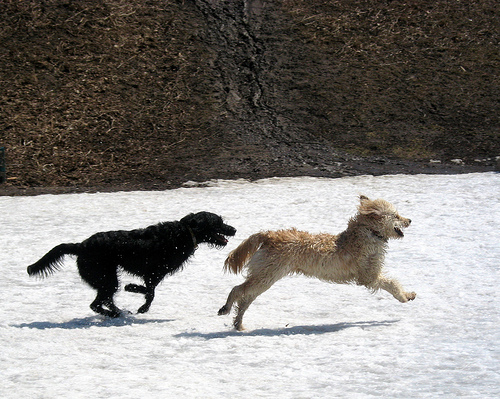

  - Caption 0: A black dog is running after a white dog in the snow .
  - Caption 1: Black dog chasing brown dog through snow
  - Caption 2: Two dogs chase each other across the snowy ground .
  - Caption 3: Two dogs play together in the snow .
  - Caption 4: Two dogs running through a low lying body of water .
Displaying the 2th image from the training set with its 5 captions:


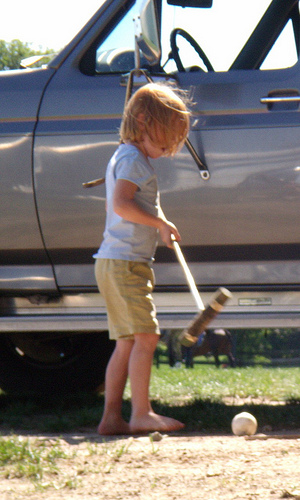

  - Caption 0: A little baby plays croquet .
  - Caption 1: A little girl plays croquet next to a truck .
  - Caption 2: The child is playing croquette by the truck .
  - Caption 3: The kid is in front of a car with a put and a ball .
  - Caption 4: The little boy is playing with a croquet hammer and ball beside the car .
Displaying the 3th image from the training set with its 5 captions:


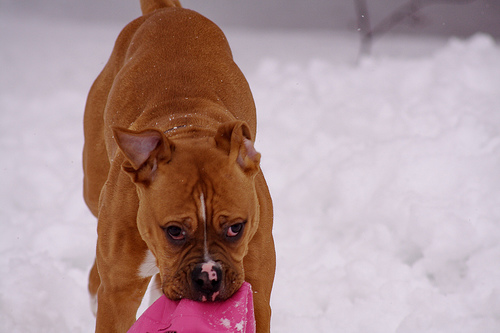

  - Caption 0: A brown dog in the snow has something hot pink in its mouth .
  - Caption 1: A brown dog in the snow holding a pink hat .
  - Caption 2: A brown dog is holding a pink shirt in the snow .
  - Caption 3: A dog is carrying something pink in its mouth while walking through the snow .
  - Caption 4: A dog with something pink in its mouth is looking forward .


In [4]:
print("\nDataset Structure:")
print(ds)

# --- Display a few Samples ---
print("\nExploring the 'train' split:")
train_data = ds['train']

for i in range (3):
    sample = train_data[i]
    print(f"Displaying the {i+1}th image from the training set with its 5 captions:")
    display(sample['image']) # In a Jupyter environment, this displays the image.

    for j in range(5):
        print(f"  - Caption {j}: {sample[f'caption_{j}']}")

## Create and Build the Vocabulary

**Here, we define a Vocabulary class to handle all text preprocessing tasks. This includes cleaning, tokenizing, and converting text to numbers**

In [5]:
class Vocabulary:
    def __init__(self, freq_threshold):
        self.freq_threshold = freq_threshold
        self.itos = {0: "<pad>", 1: "<sos>", 2: "<eos>", 3: "<unk>"}
        self.stoi = {"<pad>": 0, "<sos>": 1, "<eos>": 2, "<unk>": 3}
    
    def __len__(self):
        return len(self.itos)

    @staticmethod
    def preprocess_text(text):
        text = text.lower()
        text = re.sub(r'[^\w\s]', '', text)
        return text.split()

    def build_vocabulary(self, sentence_list):
        frequencies = Counter()
        idx = 4
        for sentence in sentence_list:
            for word in self.preprocess_text(sentence):
                frequencies[word] += 1
                if frequencies[word] == self.freq_threshold:
                    self.stoi[word] = idx
                    self.itos[idx] = word
                    idx += 1
    
    def numericalize(self, text):
        """Converts a text sentence to a sequence of numerical IDs."""
        tokenized_text = self.preprocess_text(text)
        return [self.stoi.get(token, self.stoi["<unk>"]) for token in tokenized_text]
        
    def save_vocabulary(self, file_path):
        with open(file_path, 'w') as f:
            json.dump(self.stoi, f, indent=4)
            
    @staticmethod
    def load_vocabulary(file_path):
        """Creates a Vocabulary instance from a saved JSON file."""
        vocab = Vocabulary(freq_threshold=0)
        with open(file_path, 'r') as f:
            vocab.stoi = json.load(f)
        vocab.itos = {idx: word for word, idx in vocab.stoi.items()}
        return vocab

* **Vocabulary Class**: This class centralizes text processing logic.
    - `preprocess_text`: This static method handles caption cleaning. It **converts text to lowercase**, **removes punctuation and numbers**, and **tokenizes** the string into a list of words.
    - `build_vocabulary`: This method creates the word-to-ID mapping. It only includes words that appear at least `freq_threshold` times to filter out rare words and noise.
* **Special Tokens**: The `__init__` method pre-defines four essential tokens:
    - **`<pad>`**: (Padding) A token used to fill shorter sequences to a fixed length.
    - **`<sos>`**: (Start of Sequence) A token that signals the beginning of a caption.
    - **`<eos>`**: (End of Sequence) A token that signals the end of a caption.
    - **`<unk>`**: (Unknown) A token that represents any word not present in our vocabulary.
* **Saving**: The `save_vocabulary` method **saves the `stoi` (string-to-index) dictionary to a JSON file**. This is critical for ensuring the same vocabulary is used when you later test or deploy the model.

Now we can build the vocabs 

In [6]:
vocab_file = "vocabulary.json"

if os.path.exists(vocab_file):
    # If the vocabulary file exists, load it directly.
    print(f"Found existing vocabulary file: '{vocab_file}'")
    vocab = Vocabulary.load_vocabulary(vocab_file)
    print("Vocabulary loaded from file. ✅")
else:
    # If the file doesn't exist, build it from the dataset.
    print(f"Vocabulary file not found. Building a new one...")
    
    # 1. Gather all captions from all splits.
    all_captions = []
    for split in ds:
        for example in ds[split]:
            for i in range(5):
                all_captions.append(example[f'caption_{i}'])
    
    # 2. Instantiate and build the vocabulary.
    vocab = Vocabulary(freq_threshold=5)
    vocab.build_vocabulary(all_captions)
    
    # 3. Save the newly built vocabulary for next time.
    vocab.save_vocabulary(vocab_file)
    print(f"Vocabulary built and saved to '{vocab_file}'.")

print(f"Final vocabulary size: {len(vocab)} words.")

Found existing vocabulary file: 'vocabulary.json'
Vocabulary loaded from file. ✅
Final vocabulary size: 2957 words.


## Hyperparametrs
These parameters are shared across cells:

In [7]:
# HYPER PARAMETERS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 64
embed_size = 256
hidden_size = 512
vocab_size = len(vocab)
criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi["<pad>"])


## Create the Custom PyTorch Dataset

This dataset is not our main dataset. it is just used to load the raw images for display. Our main dataset will be introduced later!

In [8]:
class FlickrDataset(Dataset):
    def __init__(self, hf_split, vocab, transform=None, seq_length=25):
        self.hf_split = hf_split
        self.vocab = vocab
        self.transform = transform
        self.seq_length = seq_length

    def __len__(self):
        return len(self.hf_split) * 5

    def __getitem__(self, index):
        image_idx = index // 5
        caption_idx = index % 5
        data_point = self.hf_split[image_idx]

        image = data_point['image'].convert("RGB")
        caption = data_point[f'caption_{caption_idx}']

        if self.transform:
            image = self.transform(image)
            
        return image, None, None

In [10]:
# Define the pipeline of image transformations
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    ),
])

seq_length = 25

val_dataset = FlickrDataset(ds['validation'], vocab, transform=image_transforms, seq_length=seq_length)
test_dataset = FlickrDataset(ds['test'], vocab, transform=image_transforms, seq_length=seq_length)

* **`image_transforms`**: This `Compose` pipeline defines the steps for image processing that will be passed to our `FlickrDataset`.
    -   `Resize`: Sets all images to 224x224 pixels.
    -   `ToTensor`: Converts images to PyTorch tensors.
    -   `Normalize`: Normalizes tensors using ImageNet's mean and standard deviation.


**The train and test split part is not needed because the hugging face data is already splited**

In [11]:
def save_checkpoint(state, filename="image_captioning_checkpoint.pth.tar"):
    """Saves the model's state to a file."""
    print("=> Saving checkpoint")
    torch.save(state, filename)

* **`save_checkpoint`**: This function is crucial for long training runs. It saves the model's `state_dict` (its learned weights), the optimizer's state, and the current epoch number into a single `.tar` file. If your training is interrupted, you can write a corresponding `load_checkpoint` function to resume exactly where you left off.

## The Modified Encoder (for Attention)

For the attention mechanism to work, the encoder must provide a grid of feature vectors, each corresponding to a different region of the image. We can no longer squash all the spatial information into a single vector.

Tasks Covered:

* Use a pre-trained CNN.

* Remove the final pooling and fully connected layers to preserve the spatial feature map.

* Examine the output dimensions.

In [12]:
class EncoderCNN_Attention(nn.Module):
    def __init__(self):
        """Initializes the spatial feature extractor."""
        super(EncoderCNN_Attention, self).__init__()
        # Load a pretrained EfficientNet_B0
        efficientnet = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        
        # We don't need the final two layers (pooling and fc)
        modules = list(efficientnet.children())[:-2]
        self.resnet = nn.Sequential(*modules)
        
        # The output of the ResNet backbone will have a certain number of channels
        # For EfficientNet_B0, this is 1280.
        self.feature_dim = 1280

    def forward(self, images):
        """
        Forward pass to extract a grid of features.
        """
        # Get features from the backbone: shape (batch_size, 1280, H/32, W/32)
        # For a 224x224 image, this is (batch_size, 1280, 7, 7)
        features = self.resnet(images)
        
        # Reshape the features to be more intuitive for attention
        batch_size, feature_dim, height, width = features.shape
        # Flatten the spatial dimensions: (batch_size, 1280, 49)
        features = features.view(batch_size, feature_dim, -1)
        # Transpose to (batch_size, 49, 1280)
        features = features.permute(0, 2, 1)
        
        return features


In [13]:
# --- Inspect the Attention Encoder ---
print("--- Initializing Attention Encoder ---")
encoder_att = EncoderCNN_Attention()

# Create a dummy image tensor
dummy_images = torch.randn(5, 3, 224, 224)

# Pass it through the encoder
spatial_features = encoder_att(dummy_images)

print(f"Shape of output spatial feature map: {spatial_features.shape}")
print("Encoder for Attention initialized successfully. ✅")

--- Initializing Attention Encoder ---
Shape of output spatial feature map: torch.Size([5, 49, 1280])
Encoder for Attention initialized successfully. ✅


* **Preserving Spatial Data**: We use a **EfficientNet_B0** model and remove its final layers (`avgpool` and `fc`). The output is now a 3D tensor `(batch_size, 1280, 7, 7)`. This is our **grid of features**, where each of the `7x7=49` locations represents a different region of the image, and each region is described by a 2048-dimensional vector.
* **Reshaping for Convenience**: We reshape the output to `(batch_size, 49, 1280)`. This format is easier to work with, representing a batch of images, where each image has **49 regions**, and each region has **1280 features**.

## The Attention Mechanism

This module is the heart of the new architecture. At each step of generating a word, it will take the decoder's current "thought" (its hidden state) and compare it against all 49 image regions to decide which ones are most important.

Tasks Covered:

* Implement the attention weight calculation.

* Normalize weights using Softmax.

* Produce a context vector (weighted sum of image features).

In [14]:
class Attention(nn.Module):
    def __init__(self, encoder_dim, decoder_hidden_dim, attention_dim):
        """
        Initializes the Attention module.
        Args:
            encoder_dim (int): Feature dimension of the encoder output (1280).
            decoder_hidden_dim (int): Dimension of the decoder's hidden state.
            attention_dim (int): The dimension of the internal attention space.
        """
        super(Attention, self).__init__()
        # Linear layers to transform the inputs
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_hidden_dim, attention_dim)
        self.full_att = nn.Linear(attention_dim, 1)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        """
        Forward pass for calculating attention.
        """
        # Pass inputs through their respective linear layers
        att1 = self.encoder_att(encoder_out)   # (batch_size, num_pixels, attention_dim)
        att2 = self.decoder_att(decoder_hidden) # (batch_size, attention_dim)

        # Add the two transformed vectors (broadcasting att2)
        # Then apply ReLU and the final attention layer
        # att2.unsqueeze(1) makes its shape (batch_size, 1, attention_dim)
        attention_scores = self.full_att(self.relu(att1 + att2.unsqueeze(1))).squeeze(2)
        
        # Apply softmax to get the attention weights (alpha)
        alpha = self.softmax(attention_scores)
        
        # Calculate the context vector (weighted sum of encoder features)
        context_vector = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
        
        return context_vector, alpha

* **Weight Calculation**: The `forward` pass implements the formula `e = f(W_h*h, W_a*a)`. `att1` corresponds to the weighted image features (`W_a*a`), and `att2` corresponds to the weighted hidden state (`W_h*h`). We add them, apply a non-linearity (`ReLU`), and pass them through a final linear layer to get the raw attention scores.
* **Softmax Normalization**: `nn.Softmax(dim=1)` is applied to these scores. This converts them into a probability distribution, where the sum of all 49 weights is 1. A higher weight means that region is more important for the current word.
* **Context Vector (`z_t`)**: This is the final output. It's a weighted average of all 49 image region vectors. If the model is trying to generate the word "dog", the regions of the image containing the dog will have high weights, and the resulting context vector will be dominated by the visual features of the dog.

## The Attention-Based Decoder

The decoder must now be modified to use the Attention module at every step of the word generation process.

Tasks Covered:

* Integrate the attention mechanism.

* Feed the context vector and previous word's embedding into the LSTM at each step.

In [15]:
class DecoderRNN_Attention(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, encoder_dim=1280, dropout=0.5):
        super(DecoderRNN_Attention, self).__init__()
        self.encoder_dim = encoder_dim
        self.hidden_size = hidden_size
        self.vocab_size = vocab_size

        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.attention = Attention(encoder_dim, hidden_size, 512)
        
        # The input to the LSTM cell is the concatenation of the embedding and context vector
        self.lstm_cell = nn.LSTMCell(embed_size + encoder_dim, hidden_size, bias=True)
        
        # Linear layers to initialize the LSTM's state from the mean of the encoder's output
        self.init_h = nn.Linear(encoder_dim, hidden_size)
        self.init_c = nn.Linear(encoder_dim, hidden_size)
        
        # Final linear layer to create the vocabulary scores
        self.fcn = nn.Linear(hidden_size, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def init_hidden_state(self, encoder_out):
        """Initializes the hidden and cell states from the encoder's output."""
        mean_encoder_out = encoder_out.mean(dim=1)
        h = self.init_h(mean_encoder_out)
        c = self.init_c(mean_encoder_out)
        return h, c

    def forward(self, encoder_out, encoded_captions, caption_lengths):
        """
        Forward pass for training (teacher forcing).
        """
        batch_size = encoder_out.size(0)
        num_pixels = encoder_out.size(1)
        
        # Sort data by caption length for more efficient processing (optional but good practice)
        caption_lengths, sort_ind = caption_lengths.sort(dim=0, descending=True)
        encoder_out = encoder_out[sort_ind]
        encoded_captions = encoded_captions[sort_ind]
        
        # Get word embeddings
        embeddings = self.embedding(encoded_captions)
        
        # Initialize LSTM state
        h, c = self.init_hidden_state(encoder_out)
        
        # We won't decode at the <end> position, since we've finished generating
        decode_lengths = (caption_lengths - 1).tolist()
        
        # Tensors to hold predictions and attention weights
        predictions = torch.zeros(batch_size, max(decode_lengths), self.vocab_size).to(encoder_out.device)
        alphas = torch.zeros(batch_size, max(decode_lengths), num_pixels).to(encoder_out.device)

        # Loop one word at a time
        for t in range(max(decode_lengths)):
            # Get the batch of data that is still generating at this time step
            batch_size_t = sum([l > t for l in decode_lengths])
            
            # Get the context vector and attention weights
            context_vector, alpha = self.attention(encoder_out[:batch_size_t], h[:batch_size_t])
            
            # Prepare the LSTM input: concat(embedding, context_vector)
            lstm_input = torch.cat((embeddings[:batch_size_t, t, :], context_vector), dim=1)
            
            # Run the LSTM cell
            h, c = self.lstm_cell(lstm_input, (h[:batch_size_t], c[:batch_size_t]))
            
            # Get predictions
            preds = self.fcn(self.dropout(h))
            predictions[:batch_size_t, t, :] = preds
            alphas[:batch_size_t, t, :] = alpha
            
        return predictions, encoded_captions, decode_lengths, alphas, sort_ind


* **Step-by-Step Generation**: Unlike the previous decoder, this one runs in a `for` loop, generating one word at each time step `t`. This is necessary because the input for step `t` (the context vector) depends on the hidden state from step `t-1`.
* **Dynamic Input**: At each step, the `attention` module is called to create a new `context_vector`. This vector is then concatenated with the current word's embedding (`lstm_input = torch.cat(...)`). This combined vector is the input to the `LSTMCell`.
* **`LSTMCell`**: We use an `LSTMCell` instead of a full `LSTM` because it's designed for single-step operations, giving us direct control over the hidden state at each iteration.
* **Output**: The `forward` method now returns the predictions *and* the attention weights (`alphas`) for each step, which we will use later for visualization.

## The Full Model and Training Setup

Assembling the new components is straightforward. The training setup is nearly identical, but we'll need a new collate_fn for our DataLoader to handle the caption lengths required by the decoder.

In [16]:
# --- Collate function for the DataLoader ---
def collate_fn(data):
    # Sort data by caption length
    data.sort(key=lambda x: x[2], reverse=True)
    images, captions, cap_lens = zip(*data)

    images = torch.stack(images, 0)
    captions = torch.stack(captions, 0)
    cap_lens = torch.stack(cap_lens, 0)

    return images, captions, cap_lens

* **Returning Caption Lengths**: We will slightly modify our `FlickrDataset` to also return the true length of each caption before padding.
* **`collate_fn`**: This custom function is provided to the `DataLoader`. Its job is to take a list of individual samples and batch them together correctly. Here, it also sorts the batch by caption length, which is a standard practice for efficient RNN processing (though our loop-based decoder can handle unsorted data too).

**TO make the training extremely faster, we decided to proccess the images only once and save the results in different files.This way, we prevent the repeatitive task of encoding images at every epoch(Since the encoder is freezed, its output won't change.)**

In [18]:

def create_final_dataset_files(dataset_split, split_name, encoder, vocab, device):
    """
    A unified function to add IDs, compute features, process captions,
    and save everything into final, ready-to-use files.
    """
    print(f"\n--- Starting unified pre-processing for {split_name} split ---")
    
    # 1. Add a unique integer ID to each image row
    dataset_split = dataset_split.add_column("image_id", range(len(dataset_split)))
    
    encoder.eval()
    features_dict = {}
    samples_list = []

    with torch.no_grad():
        for item in tqdm(dataset_split, desc=f"Processing {split_name}"):
            img_id = item['image_id']
            
            # 2. Compute and store feature for this image if not already done
            if img_id not in features_dict:
                image_tensor = image_transforms(item['image']).unsqueeze(0).to(device)
                feature = encoder(image_tensor).squeeze(0).cpu()
                features_dict[img_id] = feature
            
            # 3. Process all 5 captions for this image
            for i in range(5):
                caption = item[f'caption_{i}']
                numericalized_caption = vocab.numericalize(caption)
                caption_len = len(numericalized_caption) + 2
                
                caption_vec = [vocab.stoi["<sos>"]]
                caption_vec.extend(numericalized_caption)
                caption_vec.append(vocab.stoi["<eos>"])

                # Padding
                if len(caption_vec) < seq_length:
                    caption_vec += [vocab.stoi["<pad>"]] * (seq_length - len(caption_vec))
                else:
                    caption_vec = caption_vec[:seq_length]
                    caption_vec[-1] = vocab.stoi["<eos>"]
                    caption_len = seq_length
                
                # Append the final sample tuple to our list
                samples_list.append((img_id, torch.tensor(caption_vec), torch.tensor(caption_len)))

    # 4. Save the final data structures
    feature_path = f"{split_name}_features_dict.pt"
    samples_path = f"{split_name}_samples.pkl"
    
    torch.save(features_dict, feature_path)
    print(f"Saved feature dictionary to '{feature_path}'. Contains {len(features_dict)} images.")
    
    with open(samples_path, 'wb') as f:
        pickle.dump(samples_list, f)
    print(f"Saved samples list to '{samples_path}'. Contains {len(samples_list)} captions.")

# --- How to Run This ---
encoder = EncoderCNN_Attention().to(device)
create_final_dataset_files(ds['train'], "train", encoder, vocab, device)
create_final_dataset_files(ds['validation'], "validation", encoder, vocab, device)
create_final_dataset_files(ds['test'], "test", encoder, vocab, device)
print("\nFeature pre-computation complete. ✅")


--- Starting unified pre-processing for train split ---


Processing train: 100%|██████████| 6000/6000 [01:45<00:00, 57.13it/s]


Saved feature dictionary to 'train_features_dict.pt'. Contains 6000 images.
Saved samples list to 'train_samples.pkl'. Contains 30000 captions.

--- Starting unified pre-processing for validation split ---


Processing validation: 100%|██████████| 1000/1000 [00:17<00:00, 58.32it/s]


Saved feature dictionary to 'validation_features_dict.pt'. Contains 1000 images.
Saved samples list to 'validation_samples.pkl'. Contains 5000 captions.

--- Starting unified pre-processing for test split ---


Processing test: 100%|██████████| 1000/1000 [00:17<00:00, 57.04it/s]


Saved feature dictionary to 'test_features_dict.pt'. Contains 1000 images.
Saved samples list to 'test_samples.pkl'. Contains 5000 captions.

Feature pre-computation complete. ✅


## The Training and Validation Loop for the Attention Model

The training loop is similar to the previous one, but it's adapted to handle the outputs of the attention model (predictions and attention weights) and the caption lengths. We'll use pack_padded_sequence for a more efficient and accurate loss calculation, which is a standard practice for handling variable-length sequences in RNNs.

Tasks Covered:

* Use a suitable loss function that ignores padding (handled via pack_padded_sequence).

* Complete the training and validation cycle.

* Save checkpoints at the end of each epoch.

In [19]:


def train_attention_model(model, train_loader, val_loader, optimizer, criterion, vocab, device, num_epochs, image_val_dataset):
    """The main training and validation loop for the attention model."""
    
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        # --- Training Phase ---
        model.train()
        epoch_train_loss = 0.0
        train_iterator = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        
        for images, captions, cap_lens in train_iterator:
            images = images.to(device)
            captions = captions.to(device)
            cap_lens = cap_lens.to(device)
            
            # Forward pass
            predictions, captions_sorted, decode_lengths, alphas, sort_ind = model(images, captions, cap_lens)
            
            # For loss calculation, we don't need the <start> token
            targets = captions_sorted[:, 1:]
            
            # Pack padded sequences for more efficient loss calculation
            # This ensures that padded elements are not included in the loss.
            predictions_packed = rnn_utils.pack_padded_sequence(predictions, decode_lengths, batch_first=True).data
            targets_packed = rnn_utils.pack_padded_sequence(targets, decode_lengths, batch_first=True).data
            
            # Calculate loss
            loss = criterion(predictions_packed, targets_packed)
            
            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            # Clip gradients to prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            epoch_train_loss += loss.item()
            train_iterator.set_postfix(loss=loss.item())

        avg_train_loss = epoch_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # --- Validation Phase ---
        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            val_iterator = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
            for images, captions, cap_lens in val_iterator:
                images, captions, cap_lens = images.to(device), captions.to(device), cap_lens.to(device)
                predictions, captions_sorted, decode_lengths, _, _ = model(images, captions, cap_lens)
                targets = captions_sorted[:, 1:]
                
                predictions_packed = rnn_utils.pack_padded_sequence(predictions, decode_lengths, batch_first=True).data
                targets_packed = rnn_utils.pack_padded_sequence(targets, decode_lengths, batch_first=True).data
                
                loss = criterion(predictions_packed, targets_packed)
                epoch_val_loss += loss.item()
                val_iterator.set_postfix(loss=loss.item())

        avg_val_loss = epoch_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        
        # --- End of Epoch ---
        print(f"\nEpoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")
        
        # Save checkpoint
        checkpoint = {'epoch': epoch + 1, 'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict()}
        save_checkpoint(checkpoint, filename=f"attention_checkpoint.pth.tar")

        # --- UPDATE THIS LINE ---
        # Call the new function, passing the original image dataset
        show_example_prediction_precomputed(model, val_loader.dataset, image_val_dataset, vocab, device)
    return train_losses, val_losses

## Evaluation and Attention Heatmap Visualization

This is the most insightful part of the evaluation. We'll write a function that not only generates a caption but also visualizes the attention weights as a heatmap overlayed on the image. This lets us see what the model was "looking at" when it generated each word.

Tasks Covered:

* Implement caption generation for the attention model.

* Draw attention heatmaps for qualitative analysis.

* Display sample images with their generated captions.

In [17]:
# --- Function to reverse the normalization for display ---
def denormalize_image(tensor, mean, std):
    """Reverses the normalization on an image tensor."""
    tensor = tensor.clone() # Clone to avoid modifying the original tensor
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m) # tensor = tensor * std + mean
    return tensor

# Get the mean and std used for normalization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Use a more visually appealing style for the plot
plt.style.use('seaborn-v0_8-whitegrid')



def visualize_attention_and_caption(model, feature_dataset, image_dataset, vocab, device, mean=mean, std=std):
    """
    Generates a caption and visualizes the attention weights with a clean, multi-row layout.
    """
    print("\n--- Generating Example with Attention Visualization ---")
    model.eval()
    
    # 1. Select a random sample and fetch its data
    idx = random.randint(0, len(feature_dataset) - 1)
    print(f"index = {idx}")
    print(f"feature = {len(feature_dataset)}")
    print(f"dataset = {len(image_dataset)}")
    features, _, _ = feature_dataset[idx]
    features = features.to(device)
    
    # Get the original PIL image for high-quality display
    original_image_pil, _, _ = image_dataset[idx]
    
    # Create the tensor version for denormalization
    image_display = denormalize_image(original_image_pil.cpu(), mean, std).permute(1, 2, 0)
    
    # 2. Generate the caption AND get the attention weights
    generated_caption_text, attention_weights = model.generate_caption(features, vocab)
    generated_words = generated_caption_text.split()
    
    # 3. Set up the plot layout
    num_words = len(generated_words)
    cols = 5  # Number of heatmaps per row
    heatmap_rows = (num_words + cols - 1) // cols
    
    # Create a figure with a GridSpec layout
    fig = plt.figure(figsize=(15, 4 + 3 * heatmap_rows))
    gs = GridSpec(1 + heatmap_rows, cols, figure=fig)

    # --- Plot the original image in the top row ---
    ax_main = fig.add_subplot(gs[0, :]) # Span all columns in the first row
    ax_main.imshow(image_display)
    ax_main.set_title(f"Generated Caption: {textwrap.fill(generated_caption_text, 80)}", fontsize=16)
    ax_main.axis('off')
    
    # --- Plot the attention heatmaps in the subsequent rows ---
    for i in range(num_words):
        if i >= len(attention_weights): break

        # Calculate grid position
        row_idx = 1 + (i // cols)
        col_idx = i % cols
        
        ax = fig.add_subplot(gs[row_idx, col_idx])
        ax.imshow(image_display) # Base image
        ax.set_title(generated_words[i], fontsize=12)
        
        # Reshape and upscale the attention map
        attention_map = np.resize(attention_weights[i], (7, 7))
        upscaled_map = skimage.transform.resize(attention_map, image_display.shape[:2])
        
        # Overlay heatmap
        ax.imshow(upscaled_map, alpha=0.6, cmap='jet')
        ax.axis('off')

    plt.tight_layout(pad=0.5, rect=[0, 0, 1, 0.97])
    plt.show()
    
    model.train()

We write another function to just display and image and its generated caption(attention maps won't be displayed). This function is used during the training phase, where after each epoch, we will run this function on a randomly sampled data.

In [23]:
# New display function for the fast, attention-based model
def show_example_prediction_by_id(model, feature_dataset, image_dataset, vocab, device, idx):
    """
    Selects a random sample, gets its pre-computed features for the model AND
    its original image for display, then shows the generated caption.
    """
    model.eval()
        
    # 1. Get FEATURES for the model from the precomputed dataset
    features, _, _ = feature_dataset[idx]
    features = features.to(device)
    
    # 2. Get the original IMAGE for display from the original image-based dataset
    original_image, _, _ = image_dataset[idx]
    
    # 3. Generate the caption using the pre-computed features
    # This calls the `generate_caption` method we defined for the DecoderOnly model
    generated_caption, attention_weights = model.generate_caption(features, vocab)
    print(generated_caption)
    
    # 4. Display the original image with the new caption
    print("\n--- Example Prediction (Pre-computed) ---")
    denormalized_img = denormalize_image(original_image.cpu(), mean, std).permute(1, 2, 0)
    plt.imshow(denormalized_img)
    plt.title(f"Generated: {textwrap.fill(generated_caption, 40)}")
    plt.axis('off')
    plt.show()
    
    model.train()
    return generated_caption

def show_example_prediction_precomputed(model, feature_dataset, image_dataset, vocab, device):
    """
    Selects a random sample, gets its pre-computed features for the model AND
    its original image for display, then shows the generated caption.
    """
    
    # Select a random sample index
    idx = random.randint(0, len(feature_dataset) - 1)
    return show_example_prediction_by_id(model, feature_dataset, image_dataset, vocab, device, idx)

This function is just a wrapper.

In [19]:
def generate_and_visualize_attention(model, feature_dataset, image_dataset, vocab, device, num_examples=5, mean=mean, std=std):
    """
    Generates captions for random images and visualizes the attention weights.
    """    
    for _ in range(num_examples):
        visualize_attention_and_caption(model, feature_dataset, image_dataset, vocab, device, mean=mean, std=std)

## Main dataset
Now, we are ready to define our main dataset. since we have precomputed the encoded images and captions earlier, we need to load those files and use them.

In [20]:
# File: 04_attention_model_fast.py (Your main script)

class FlickrDataset_Final(Dataset):
    """
    A simple and robust Dataset that loads fully pre-processed data from files.
    """
    def __init__(self, feature_file, samples_file):
        print(f"Loading feature dictionary from {feature_file}...")
        self.features_dict = torch.load(feature_file)
        
        print(f"Loading samples list from {samples_file}...")
        with open(samples_file, 'rb') as f:
            self.samples = pickle.load(f)
        
        print("Dataset loaded successfully.")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        # 1. Get the pre-processed sample
        img_id, caption_vec, cap_len = self.samples[index]
        
        # 2. Get the corresponding feature tensor using the ID
        features = self.features_dict[img_id]
        
        return features, caption_vec, cap_len

# 1. Create instances of the NEW, simple dataset
train_dataset_final = FlickrDataset_Final("train_features_dict.pt", "train_samples.pkl")
val_dataset_final = FlickrDataset_Final("validation_features_dict.pt", "validation_samples.pkl")
test_dataset_final = FlickrDataset_Final("test_features_dict.pt", "test_samples.pkl")

# # Use the same collate_fn and create your DataLoaders
train_loader_precomp = DataLoader(train_dataset_final, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, num_workers=4, pin_memory=True)
val_loader_precomp = DataLoader(val_dataset_final, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, num_workers=4, pin_memory=True)
test_loader_precomp = DataLoader(test_dataset_final, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, num_workers=4, pin_memory=True)


Loading feature dictionary from train_features_dict.pt...
Loading samples list from train_samples.pkl...
Dataset loaded successfully.
Loading feature dictionary from validation_features_dict.pt...
Loading samples list from validation_samples.pkl...
Dataset loaded successfully.
Loading feature dictionary from test_features_dict.pt...
Loading samples list from test_samples.pkl...
Dataset loaded successfully.


## Running the Training and Evaluation

Now, let's tie everything together by calling our training function and then visualizing the final results.

Tasks Covered:

* Plot training and validation loss curves.

* Show final generated captions and their attention maps.

### Our model
Since we have encoded images and save them, our model is just the decoder part:

In [21]:
class DecoderOnly_AttentionModel(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, encoder_dim=1280):
        super().__init__()
        # The model is now just the decoder
        self.decoder = DecoderRNN_Attention(embed_size, hidden_size, vocab_size, encoder_dim)

    def forward(self, features, captions, caption_lengths):
        # The forward pass now directly uses the pre-computed features
        outputs = self.decoder(features, captions, caption_lengths)
        return outputs
    def generate_caption(self, features, vocab, max_length=25):
        """
        Generates a caption AND returns the attention weights for visualization.
        """
        self.eval()
        generated_caption_words = []
        attention_weights = [] # <-- We will store the weights here

        with torch.no_grad():
            features = features.unsqueeze(0)
            h, c = self.decoder.init_hidden_state(features)
            input_word_idx = torch.tensor([vocab.stoi['<sos>']], device=features.device)

            for _ in range(max_length):
                embeddings = self.decoder.embedding(input_word_idx)
                
                # Get context vector AND the attention weights (alpha)
                context_vector, alpha = self.decoder.attention(features, h)
                
                lstm_input = torch.cat((embeddings, context_vector), dim=1)
                h, c = self.decoder.lstm_cell(lstm_input, (h, c))
                preds = self.decoder.fcn(h)
                predicted_idx = preds.argmax(1)
                
                word = vocab.itos[predicted_idx.item()]
                generated_caption_words.append(word)
                
                # --- Store the attention weights ---
                attention_weights.append(alpha.squeeze(0).cpu().numpy())
                
                if word == '<eos>':
                    break
                
                input_word_idx = predicted_idx
        
        self.train()
        
        return " ".join(generated_caption_words), attention_weights

# 4. Update your model instantiation and training call
model_fast = DecoderOnly_AttentionModel(embed_size, hidden_size, vocab_size).to(device)
optimizer = torch.optim.Adam(model_fast.parameters(), lr=1e-4) # Re-init optimizer for new model
num_epochs_att = 50

Epoch 1/50 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 28.09it/s, loss=4.23]



Epoch [1/50], Train Loss: 4.9297, Val Loss: 4.2454
=> Saving checkpoint
a dog is running in the snow <eos>

--- Example Prediction (Pre-computed) ---


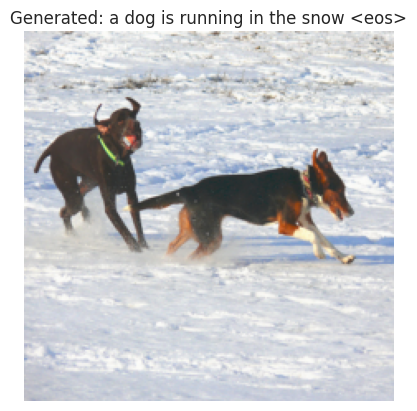

Epoch 2/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.91it/s, loss=3.8] 



Epoch [2/50], Train Loss: 4.0449, Val Loss: 3.8374
=> Saving checkpoint
a black dog is running through the grass <eos>

--- Example Prediction (Pre-computed) ---


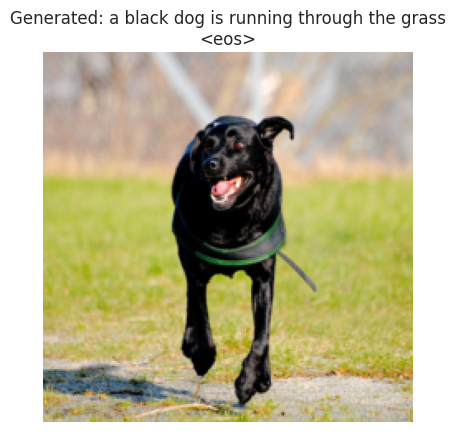

Epoch 3/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 28.48it/s, loss=3.58]



Epoch [3/50], Train Loss: 3.7081, Val Loss: 3.6134
=> Saving checkpoint
a woman in a red shirt and a woman is standing on a beach <eos>

--- Example Prediction (Pre-computed) ---


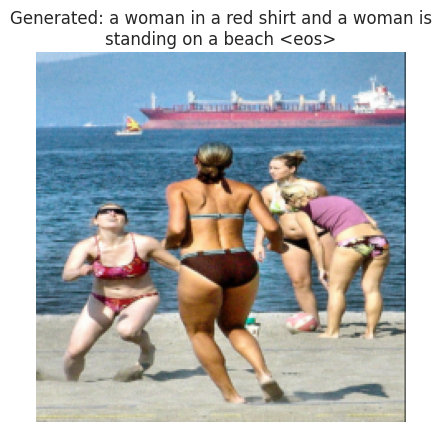

Epoch 4/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.81it/s, loss=3.43]



Epoch [4/50], Train Loss: 3.4895, Val Loss: 3.4650
=> Saving checkpoint
a man in a red shirt is standing in a <unk> <eos>

--- Example Prediction (Pre-computed) ---


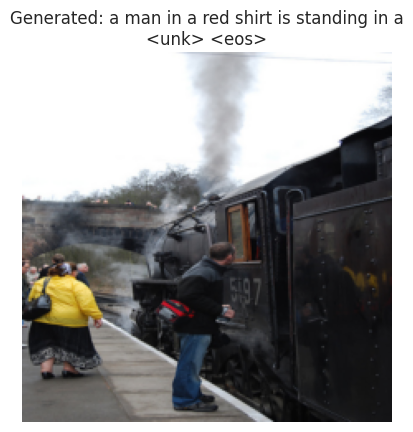

Epoch 5/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.94it/s, loss=3.34]



Epoch [5/50], Train Loss: 3.3228, Val Loss: 3.3568
=> Saving checkpoint
a man is riding a bike on a bike <eos>

--- Example Prediction (Pre-computed) ---


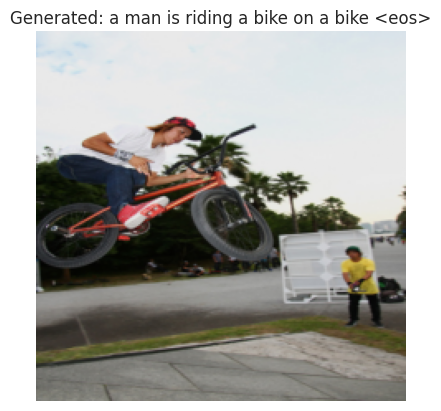

Epoch 6/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.00it/s, loss=3.21]



Epoch [6/50], Train Loss: 3.1882, Val Loss: 3.2756
=> Saving checkpoint
a dog is running through the snow <eos>

--- Example Prediction (Pre-computed) ---


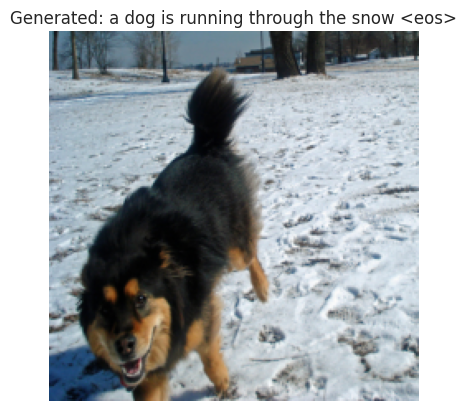

Epoch 7/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.62it/s, loss=3.12]



Epoch [7/50], Train Loss: 3.0743, Val Loss: 3.2128
=> Saving checkpoint
two dogs are running in a field <eos>

--- Example Prediction (Pre-computed) ---


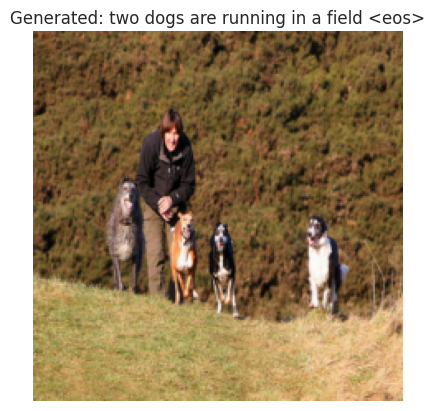

Epoch 8/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.50it/s, loss=3.02]



Epoch [8/50], Train Loss: 2.9742, Val Loss: 3.1641
=> Saving checkpoint
a dog is running through the snow <eos>

--- Example Prediction (Pre-computed) ---


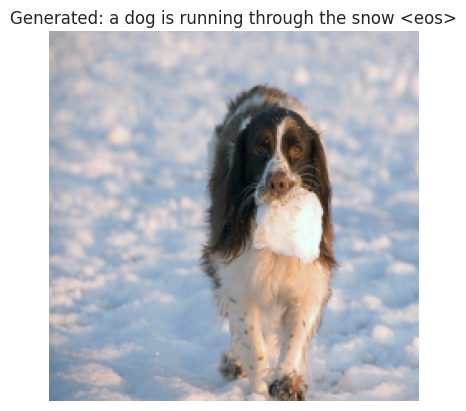

Epoch 9/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.17it/s, loss=2.98]



Epoch [9/50], Train Loss: 2.8847, Val Loss: 3.1269
=> Saving checkpoint
a group of people are standing in a <unk> of a <unk> <eos>

--- Example Prediction (Pre-computed) ---


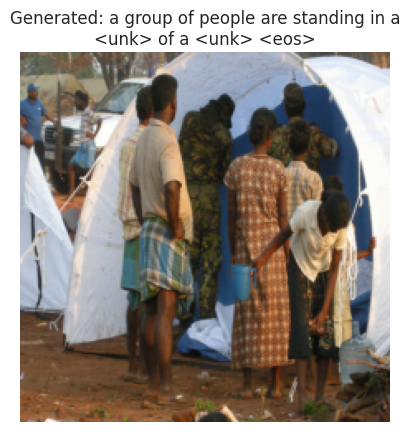

Epoch 10/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.46it/s, loss=2.91]



Epoch [10/50], Train Loss: 2.8040, Val Loss: 3.0996
=> Saving checkpoint
a person is riding a <unk> in the air <eos>

--- Example Prediction (Pre-computed) ---


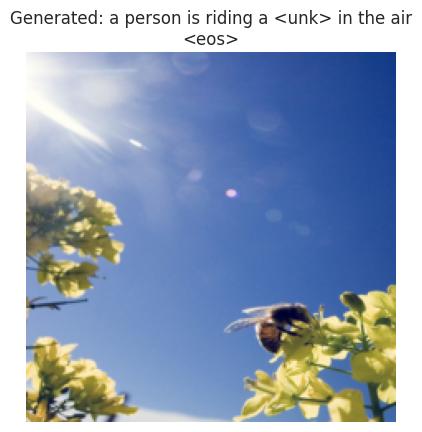

Epoch 11/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.35it/s, loss=2.89]



Epoch [11/50], Train Loss: 2.7292, Val Loss: 3.0761
=> Saving checkpoint
two women are standing in a <unk> <eos>

--- Example Prediction (Pre-computed) ---


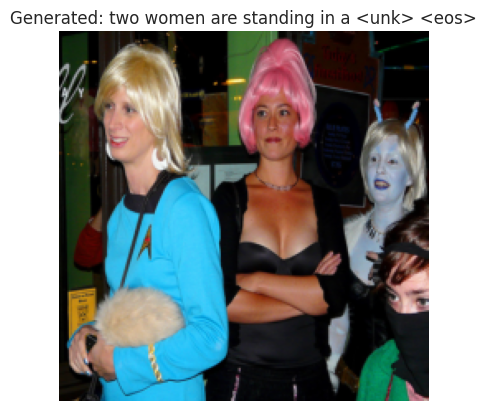

Epoch 12/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.82it/s, loss=2.88]



Epoch [12/50], Train Loss: 2.6598, Val Loss: 3.0584
=> Saving checkpoint
a boy jumps off a ramp <eos>

--- Example Prediction (Pre-computed) ---


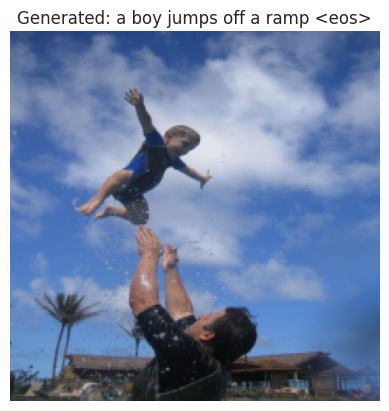

Epoch 13/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.76it/s, loss=2.79]



Epoch [13/50], Train Loss: 2.5949, Val Loss: 3.0341
=> Saving checkpoint
a woman in a black jacket is standing in front of a <unk> <unk> <eos>

--- Example Prediction (Pre-computed) ---


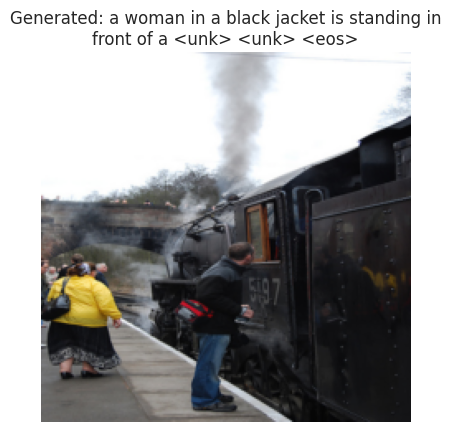

Epoch 14/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.85it/s, loss=2.81]



Epoch [14/50], Train Loss: 2.5338, Val Loss: 3.0338
=> Saving checkpoint
a group of people are playing on a beach <eos>

--- Example Prediction (Pre-computed) ---


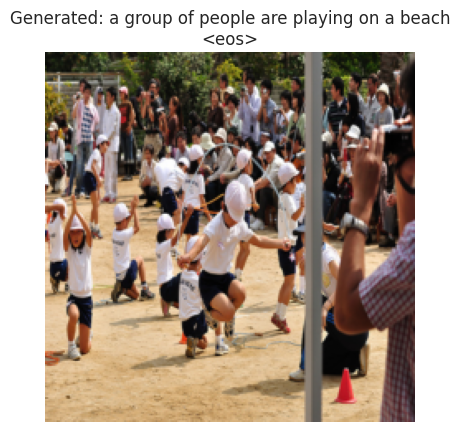

Epoch 15/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.75it/s, loss=2.81]



Epoch [15/50], Train Loss: 2.4766, Val Loss: 3.0187
=> Saving checkpoint
a man with a <unk> and a woman in a black shirt and a hat is standing on a <unk> <eos>

--- Example Prediction (Pre-computed) ---


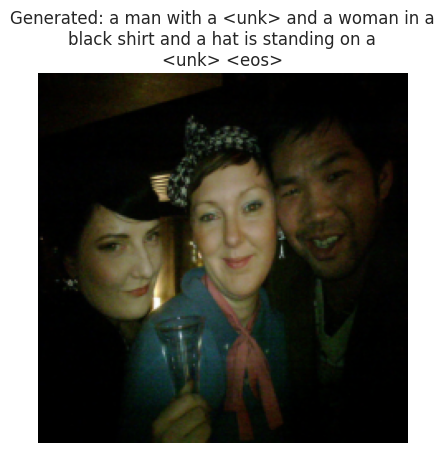

Epoch 16/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.69it/s, loss=2.73]



Epoch [16/50], Train Loss: 2.4199, Val Loss: 3.0154
=> Saving checkpoint
a man in a white jacket is standing on a rock formation <eos>

--- Example Prediction (Pre-computed) ---


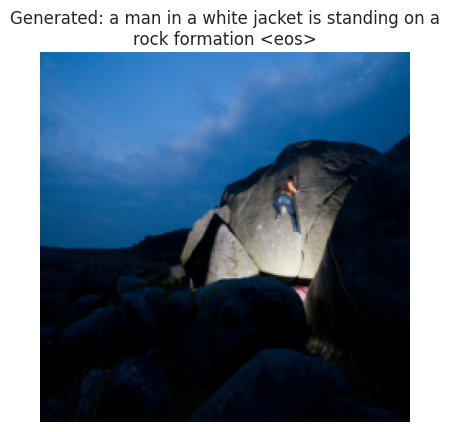

Epoch 17/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.32it/s, loss=2.69]



Epoch [17/50], Train Loss: 2.3679, Val Loss: 3.0122
=> Saving checkpoint
a black dog is running in the grass with a stick in its mouth <eos>

--- Example Prediction (Pre-computed) ---


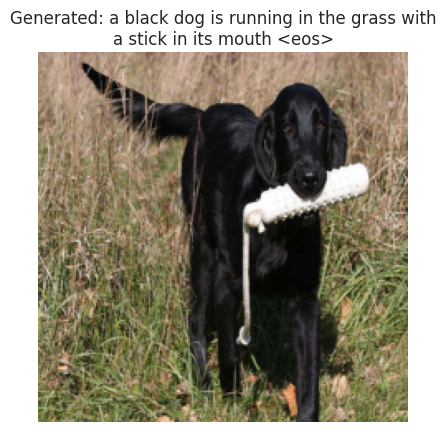

Epoch 18/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.14it/s, loss=2.72]



Epoch [18/50], Train Loss: 2.3170, Val Loss: 3.0161
=> Saving checkpoint
a dog with a ball in the air <eos>

--- Example Prediction (Pre-computed) ---


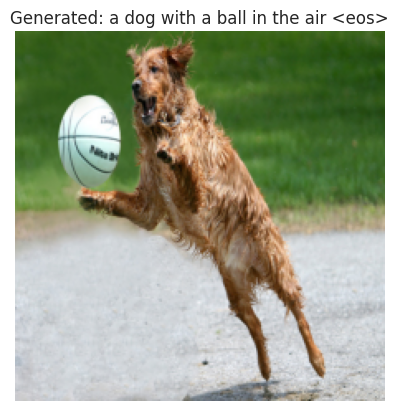

Epoch 19/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.81it/s, loss=2.74]



Epoch [19/50], Train Loss: 2.2693, Val Loss: 3.0148
=> Saving checkpoint
a man is standing on a <unk> <unk> by a man and a woman are standing on a <unk> <eos>

--- Example Prediction (Pre-computed) ---


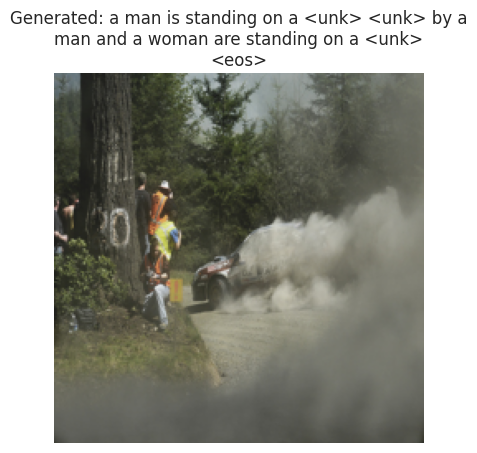

Epoch 20/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.14it/s, loss=2.69]



Epoch [20/50], Train Loss: 2.2233, Val Loss: 3.0215
=> Saving checkpoint
a man is riding a <unk> on a railing <eos>

--- Example Prediction (Pre-computed) ---


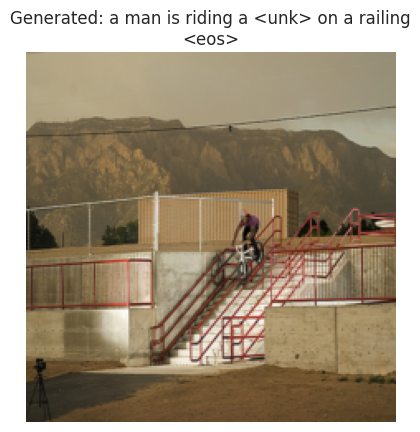

Epoch 21/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.71it/s, loss=2.65]



Epoch [21/50], Train Loss: 2.1785, Val Loss: 3.0230
=> Saving checkpoint
a person in a red jacket is snowboarding down a hill <eos>

--- Example Prediction (Pre-computed) ---


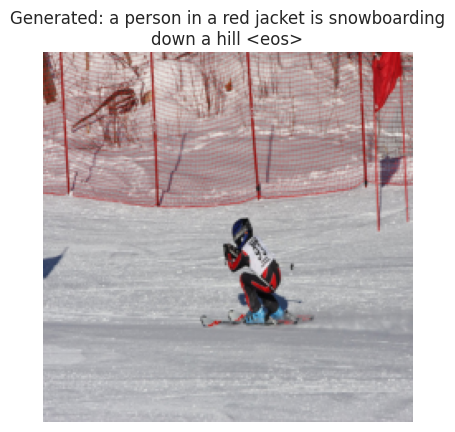

Epoch 22/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.53it/s, loss=2.7] 



Epoch [22/50], Train Loss: 2.1358, Val Loss: 3.0343
=> Saving checkpoint
two dogs are racing on a track <eos>

--- Example Prediction (Pre-computed) ---


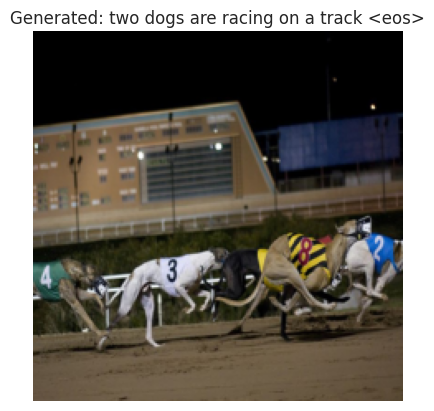

Epoch 23/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 24.69it/s, loss=2.62]



Epoch [23/50], Train Loss: 2.0933, Val Loss: 3.0441
=> Saving checkpoint
a group of people are standing on the shore of the ocean <eos>

--- Example Prediction (Pre-computed) ---


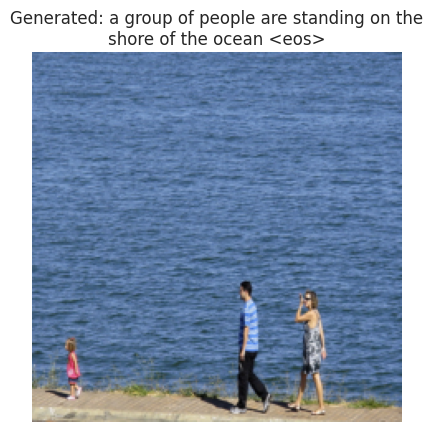

Epoch 24/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.32it/s, loss=2.7] 



Epoch [24/50], Train Loss: 2.0550, Val Loss: 3.0521
=> Saving checkpoint
people are standing in the snow and snow covered in the snow <eos>

--- Example Prediction (Pre-computed) ---


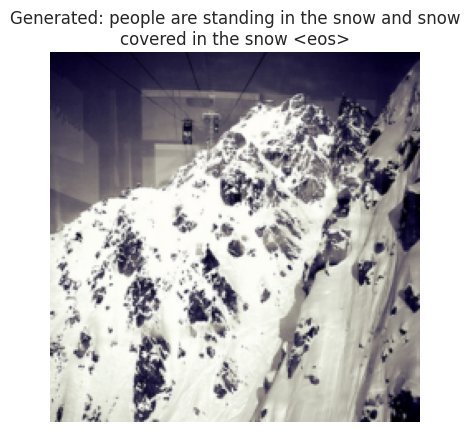

Epoch 25/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.19it/s, loss=2.69]



Epoch [25/50], Train Loss: 2.0173, Val Loss: 3.0614
=> Saving checkpoint
a man and a woman are sitting on a dock at a beach <eos>

--- Example Prediction (Pre-computed) ---


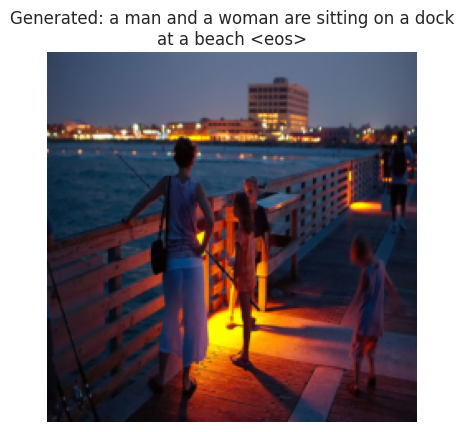

Epoch 26/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.93it/s, loss=2.7] 



Epoch [26/50], Train Loss: 1.9799, Val Loss: 3.0772
=> Saving checkpoint
a hockey player in a red uniform is trying to make a goal while another player watches the goal <eos>

--- Example Prediction (Pre-computed) ---


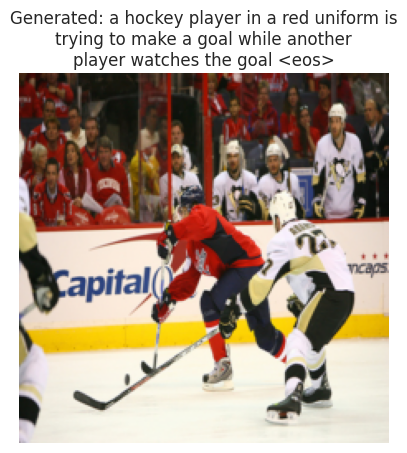

Epoch 27/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.49it/s, loss=2.69]



Epoch [27/50], Train Loss: 1.9433, Val Loss: 3.0805
=> Saving checkpoint
a football player is wearing a red and white uniform is <unk> the ball <eos>

--- Example Prediction (Pre-computed) ---


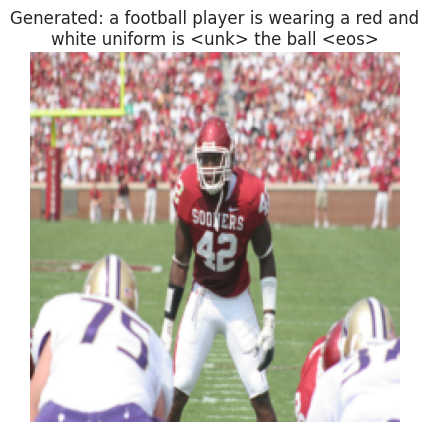

Epoch 28/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.96it/s, loss=2.66]



Epoch [28/50], Train Loss: 1.9109, Val Loss: 3.0950
=> Saving checkpoint
a man is in a boat in the water <eos>

--- Example Prediction (Pre-computed) ---


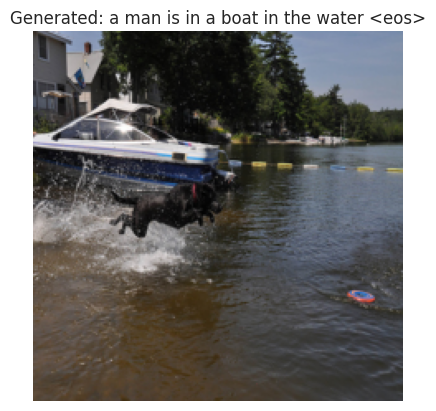

Epoch 29/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.36it/s, loss=2.68]



Epoch [29/50], Train Loss: 1.8756, Val Loss: 3.1064
=> Saving checkpoint
a small dog is laying on a rug and brown dog <eos>

--- Example Prediction (Pre-computed) ---


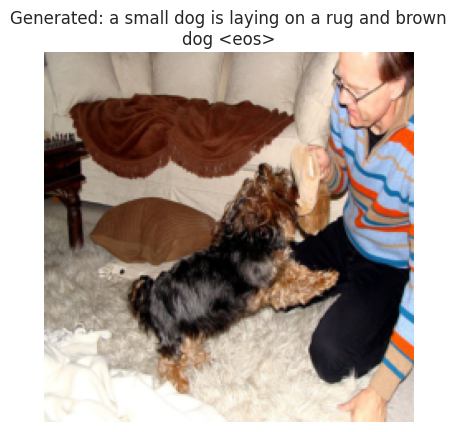

Epoch 30/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.79it/s, loss=2.68]



Epoch [30/50], Train Loss: 1.8433, Val Loss: 3.1315
=> Saving checkpoint
a group of people are standing under a tent with a tent <eos>

--- Example Prediction (Pre-computed) ---


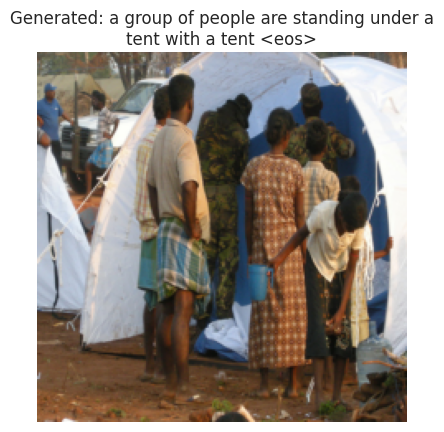

Epoch 31/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.51it/s, loss=2.71]



Epoch [31/50], Train Loss: 1.8109, Val Loss: 3.1433
=> Saving checkpoint
a <unk> <unk> is sitting on the ground <eos>

--- Example Prediction (Pre-computed) ---


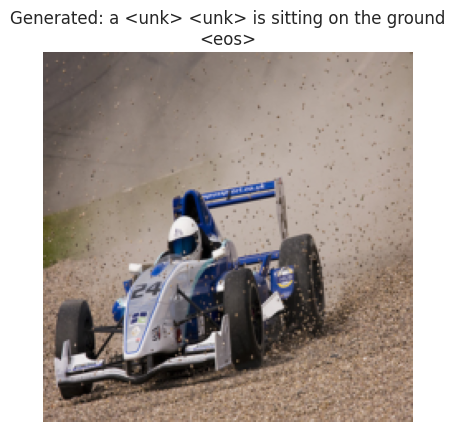

Epoch 32/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.64it/s, loss=2.71]



Epoch [32/50], Train Loss: 1.7800, Val Loss: 3.1575
=> Saving checkpoint
a man in a red shirt and black pants is walking down a street <eos>

--- Example Prediction (Pre-computed) ---


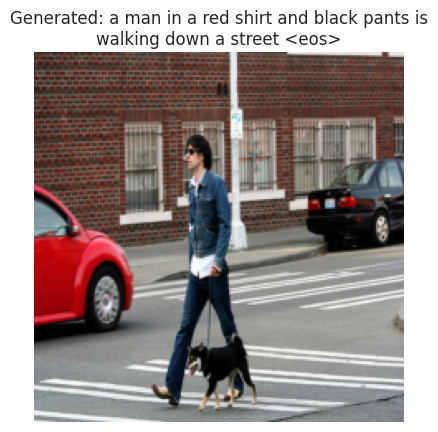

Epoch 33/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.18it/s, loss=2.68]



Epoch [33/50], Train Loss: 1.7501, Val Loss: 3.1783
=> Saving checkpoint
a boy is jumping on a <unk> in front of a crowd <eos>

--- Example Prediction (Pre-computed) ---


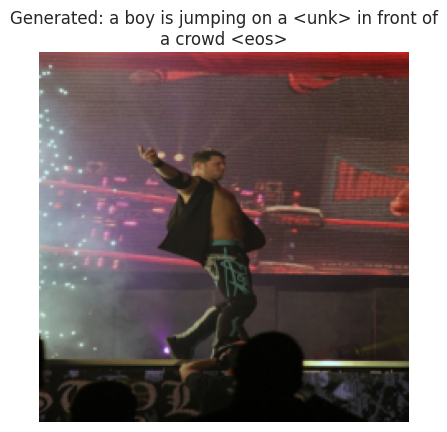

Epoch 34/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.85it/s, loss=2.71]



Epoch [34/50], Train Loss: 1.7214, Val Loss: 3.1759
=> Saving checkpoint
a man and a woman in a white dress <eos>

--- Example Prediction (Pre-computed) ---


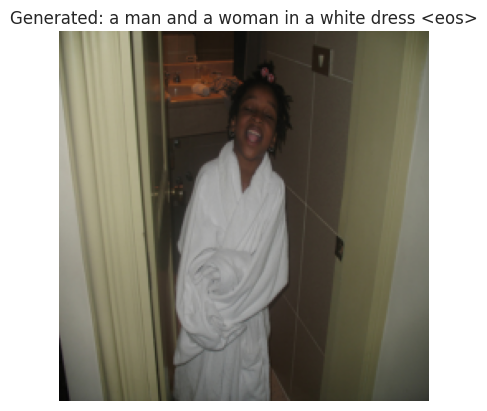

Epoch 35/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 24.93it/s, loss=2.73]



Epoch [35/50], Train Loss: 1.6945, Val Loss: 3.2001
=> Saving checkpoint
a little girl with a blue shirt and a child is sitting in a crowd of water <eos>

--- Example Prediction (Pre-computed) ---


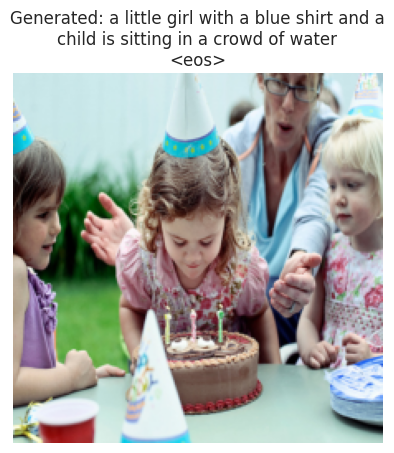

Epoch 36/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 28.05it/s, loss=2.72]



Epoch [36/50], Train Loss: 1.6661, Val Loss: 3.2163
=> Saving checkpoint
a girl in a pink dress walks through the road <eos>

--- Example Prediction (Pre-computed) ---


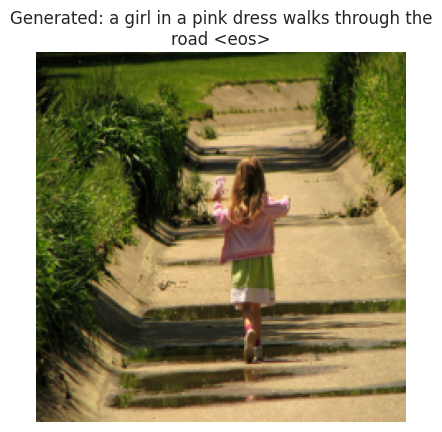

Epoch 37/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.47it/s, loss=2.73]



Epoch [37/50], Train Loss: 1.6389, Val Loss: 3.2296
=> Saving checkpoint
a woman and black dog laying down on the sidewalk <eos>

--- Example Prediction (Pre-computed) ---


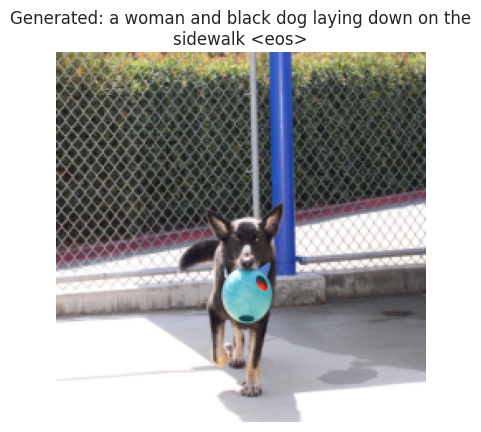

Epoch 38/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.46it/s, loss=2.76]



Epoch [38/50], Train Loss: 1.6159, Val Loss: 3.2395
=> Saving checkpoint
a young boy in a blue jacket is jumping into a stream of water <eos>

--- Example Prediction (Pre-computed) ---


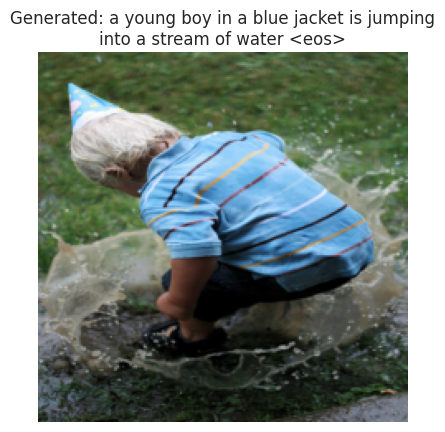

Epoch 39/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.66it/s, loss=2.72]



Epoch [39/50], Train Loss: 1.5891, Val Loss: 3.2605
=> Saving checkpoint
a black and white dog is playing with a toy <eos>

--- Example Prediction (Pre-computed) ---


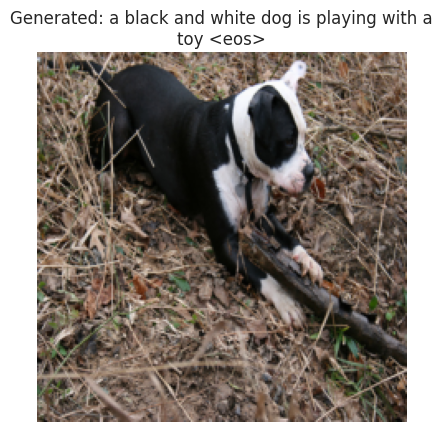

Epoch 40/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.34it/s, loss=2.78]



Epoch [40/50], Train Loss: 1.5663, Val Loss: 3.2908
=> Saving checkpoint
a man in a red coat and a woman playing with paper in front of a brick <eos>

--- Example Prediction (Pre-computed) ---


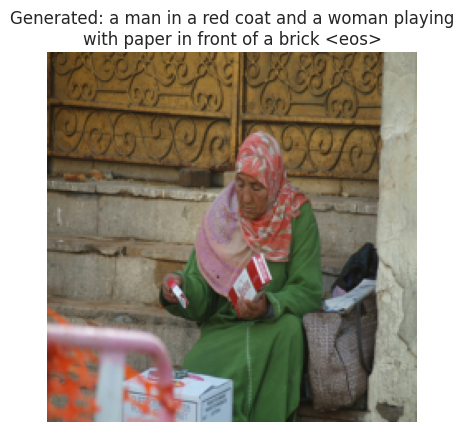

Epoch 41/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 26.32it/s, loss=2.78]



Epoch [41/50], Train Loss: 1.5432, Val Loss: 3.3194
=> Saving checkpoint
a brown dog is swimming in the water <eos>

--- Example Prediction (Pre-computed) ---


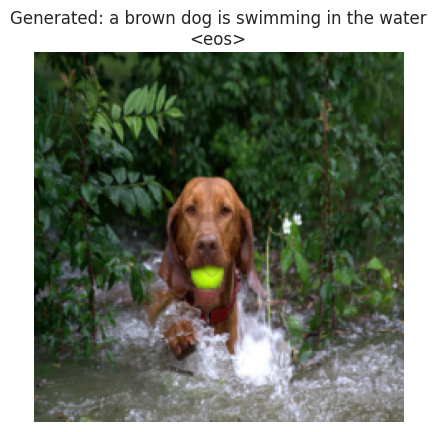

Epoch 42/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.74it/s, loss=2.79]



Epoch [42/50], Train Loss: 1.5211, Val Loss: 3.3154
=> Saving checkpoint
an older woman with a brown and white shirt is looking at a woman looking at a restaurant <eos>

--- Example Prediction (Pre-computed) ---


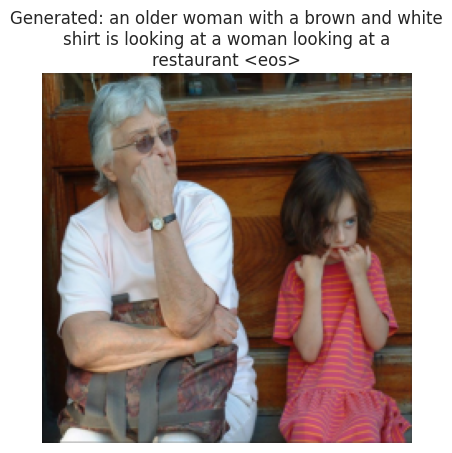

Epoch 43/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.35it/s, loss=2.77]



Epoch [43/50], Train Loss: 1.4987, Val Loss: 3.3241
=> Saving checkpoint
a boy in a white shirt and a girl is standing on the water <eos>

--- Example Prediction (Pre-computed) ---


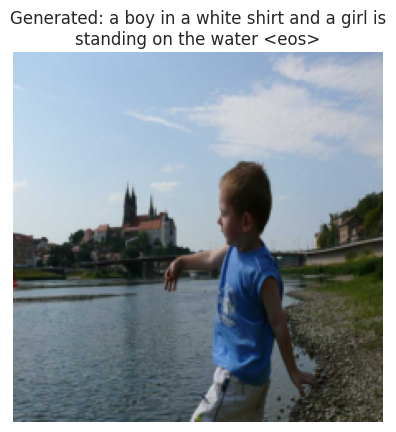

Epoch 44/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.78it/s, loss=2.85]



Epoch [44/50], Train Loss: 1.4743, Val Loss: 3.3538
=> Saving checkpoint
a football player is wearing a red and white uniform and <unk> <eos>

--- Example Prediction (Pre-computed) ---


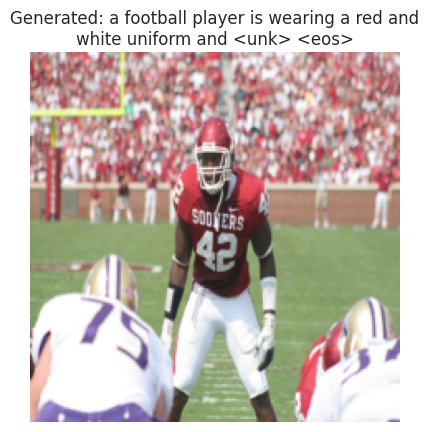

Epoch 45/50 [Val]: 100%|██████████| 79/79 [00:03<00:00, 25.74it/s, loss=2.8] 



Epoch [45/50], Train Loss: 1.4575, Val Loss: 3.3771
=> Saving checkpoint
a young girl with a <unk> in a room <eos>

--- Example Prediction (Pre-computed) ---


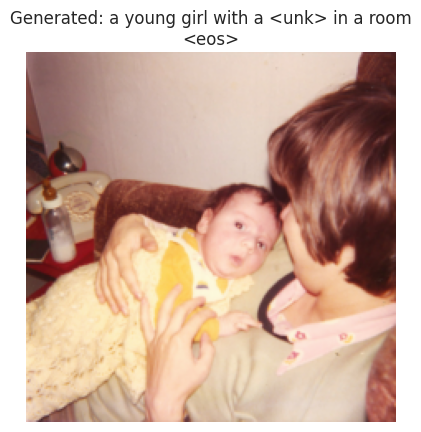

Epoch 46/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.23it/s, loss=2.79]



Epoch [46/50], Train Loss: 1.4327, Val Loss: 3.3671
=> Saving checkpoint
a woman wearing a black shirt is carrying a book in front of a store <eos>

--- Example Prediction (Pre-computed) ---


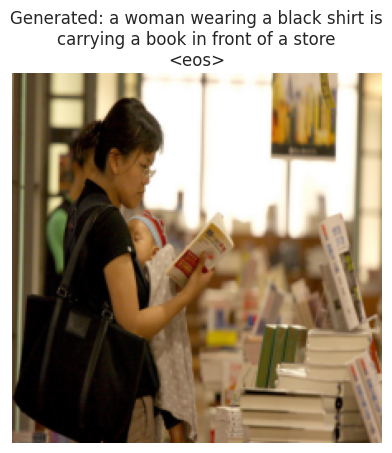

Epoch 47/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.49it/s, loss=2.8] 



Epoch [47/50], Train Loss: 1.4152, Val Loss: 3.4124
=> Saving checkpoint
two men playing rugby players on a field <eos>

--- Example Prediction (Pre-computed) ---


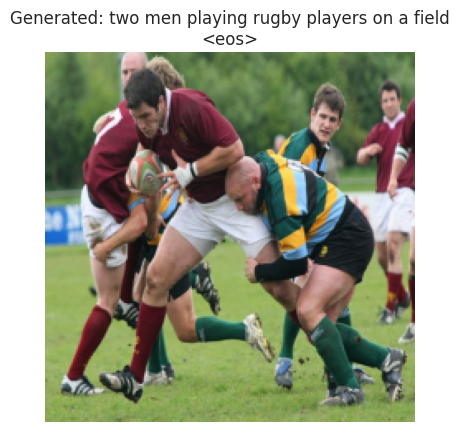

Epoch 48/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 26.48it/s, loss=2.85]



Epoch [48/50], Train Loss: 1.3957, Val Loss: 3.4177
=> Saving checkpoint
a young child is sitting on a lawn path <eos>

--- Example Prediction (Pre-computed) ---


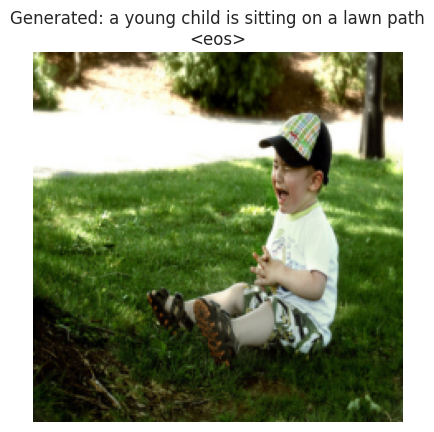

Epoch 49/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.40it/s, loss=2.88]



Epoch [49/50], Train Loss: 1.3741, Val Loss: 3.4339
=> Saving checkpoint
a small brown and black dog is jumping on a grassy path <eos>

--- Example Prediction (Pre-computed) ---


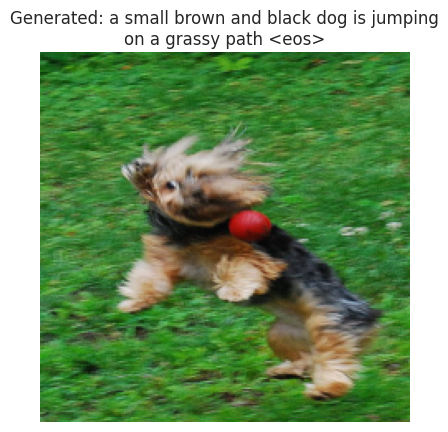

Epoch 50/50 [Val]: 100%|██████████| 79/79 [00:02<00:00, 27.77it/s, loss=2.88]



Epoch [50/50], Train Loss: 1.3549, Val Loss: 3.4563
=> Saving checkpoint
people are playing in a field <eos>

--- Example Prediction (Pre-computed) ---


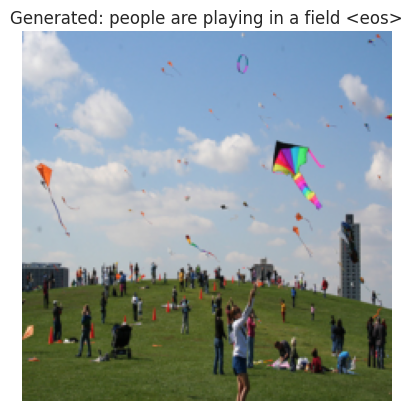

In [ ]:



# Call the same training function, but pass the NEW model and data loaders
train_losses_att, val_losses_att = train_attention_model(
    model=model_fast,
    train_loader=train_loader_precomp,
    val_loader=val_loader_precomp,
    optimizer=optimizer,
    criterion=criterion,
    vocab=vocab,
    device=device,
    num_epochs=num_epochs_att,
    image_val_dataset=val_dataset
)


--- Generating Example with Attention Visualization ---
index = 2299
feature = 5000
dataset = 5000


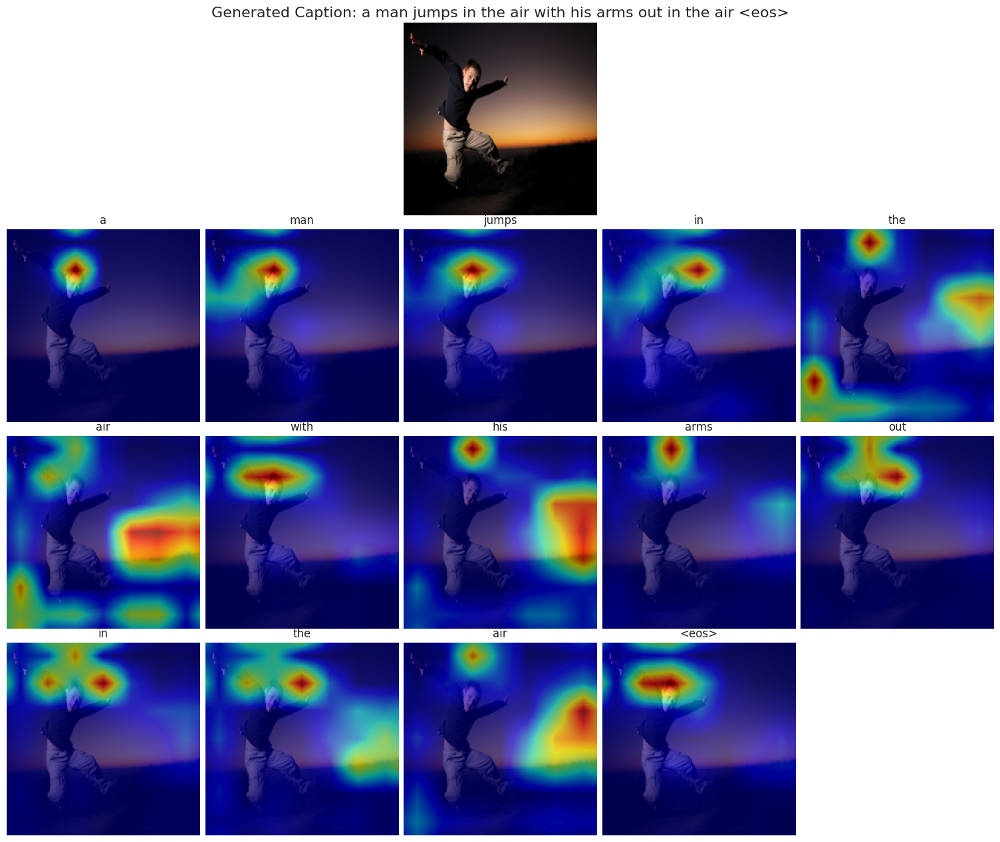

In [25]:
visualize_attention_and_caption(model_fast, val_loader_precomp.dataset, val_dataset, vocab, device)

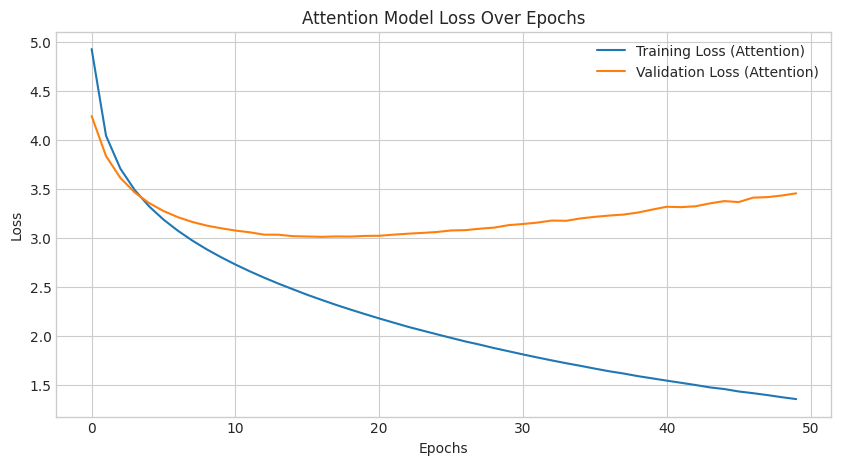


--- Final Results on Test Set (with Attention Heatmaps) ---

--- Generating Example with Attention Visualization ---
index = 1683
feature = 5000
dataset = 5000


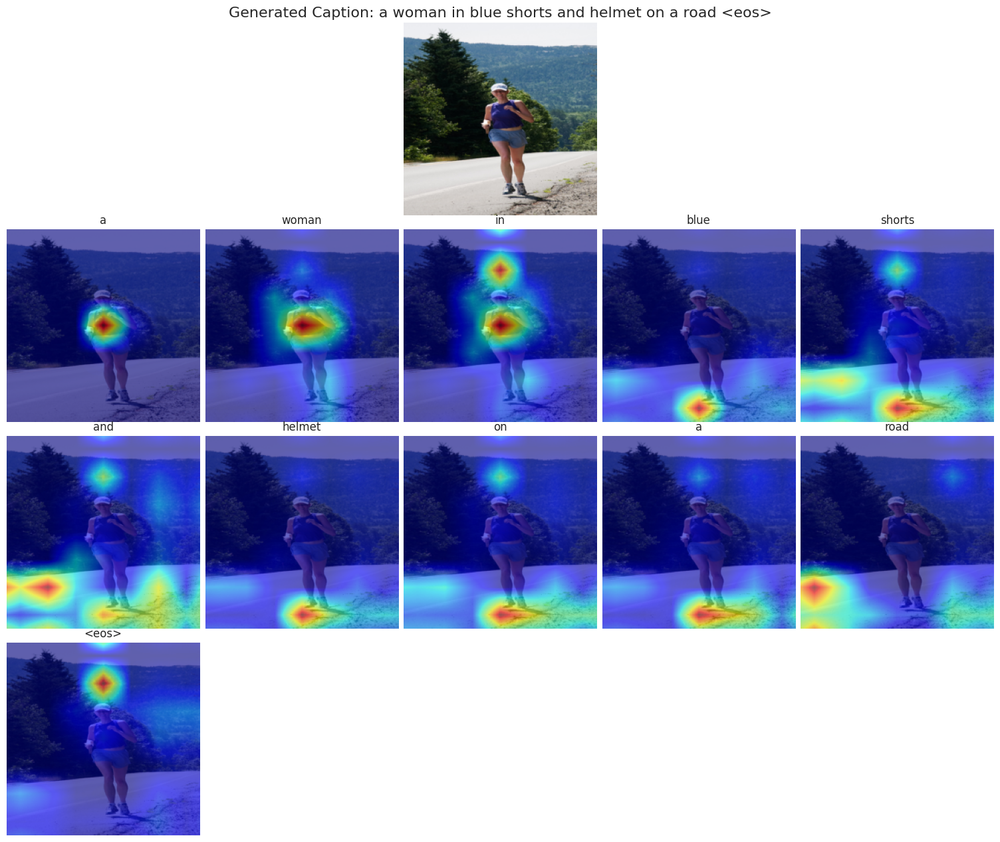


--- Generating Example with Attention Visualization ---
index = 4171
feature = 5000
dataset = 5000


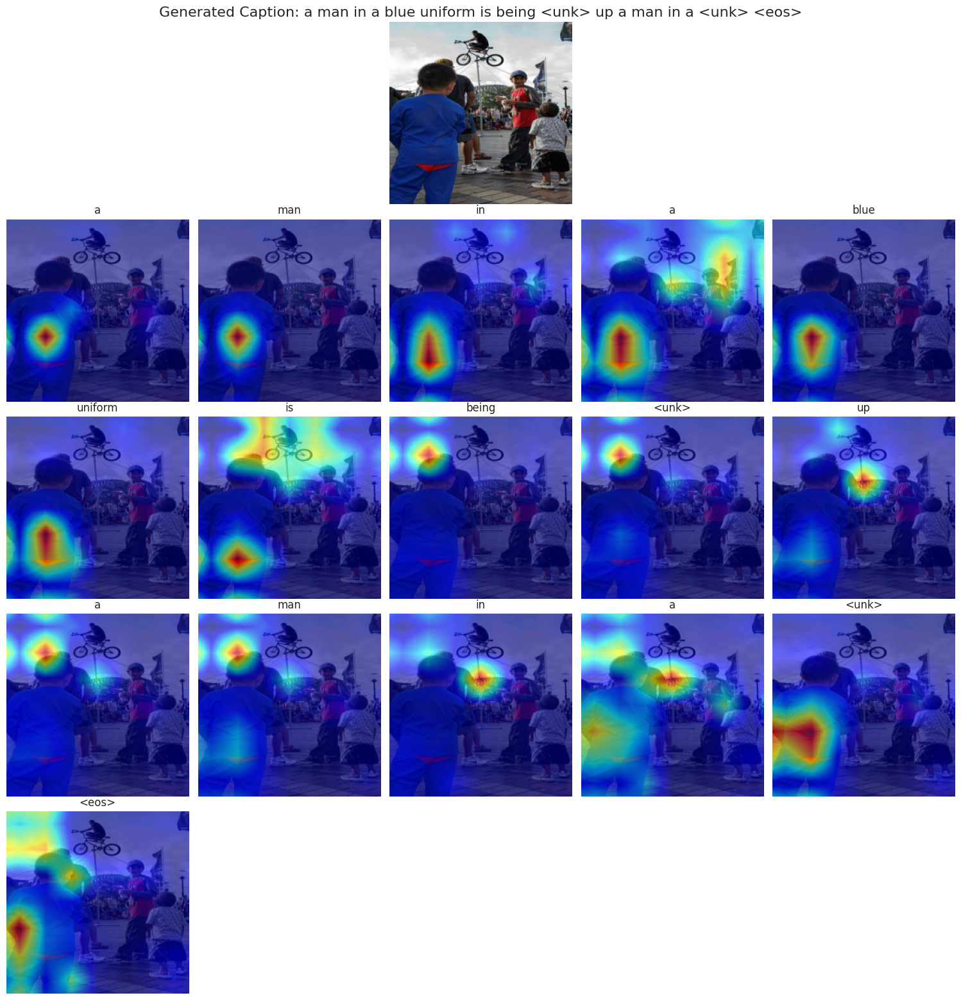


--- Generating Example with Attention Visualization ---
index = 4800
feature = 5000
dataset = 5000


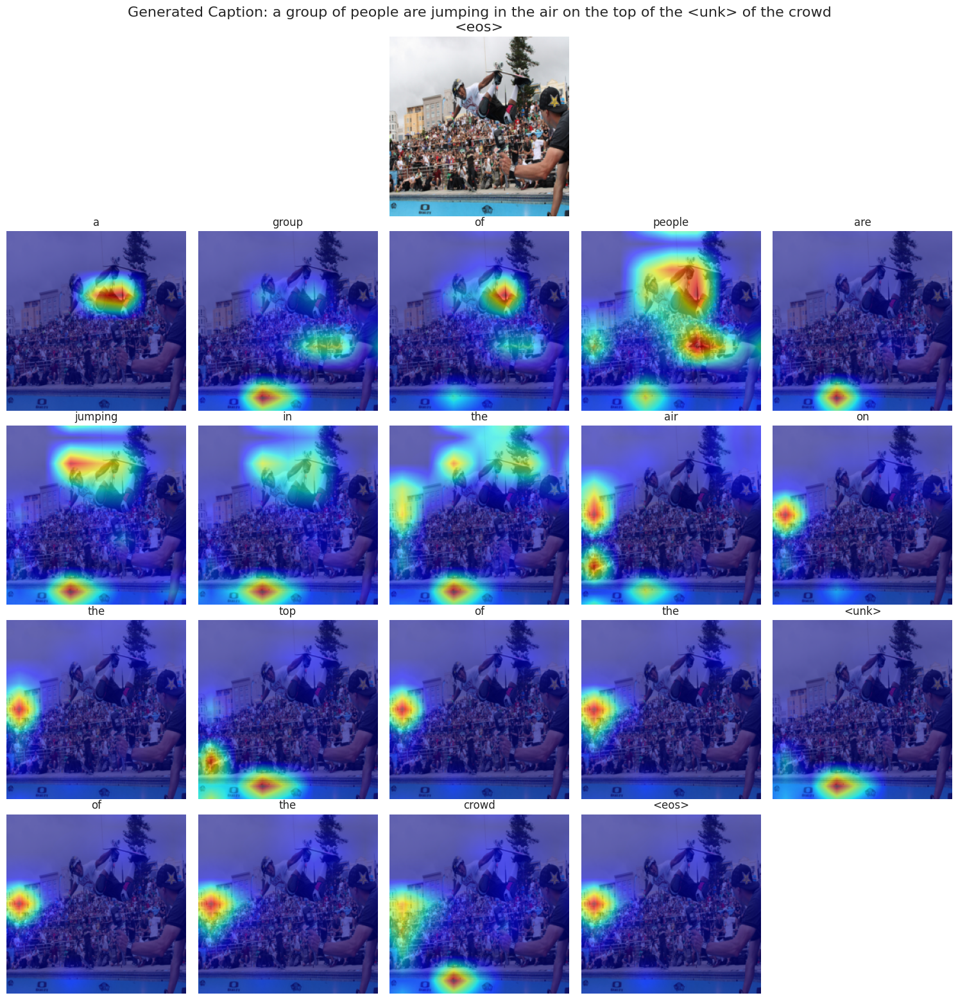


--- Generating Example with Attention Visualization ---
index = 1048
feature = 5000
dataset = 5000


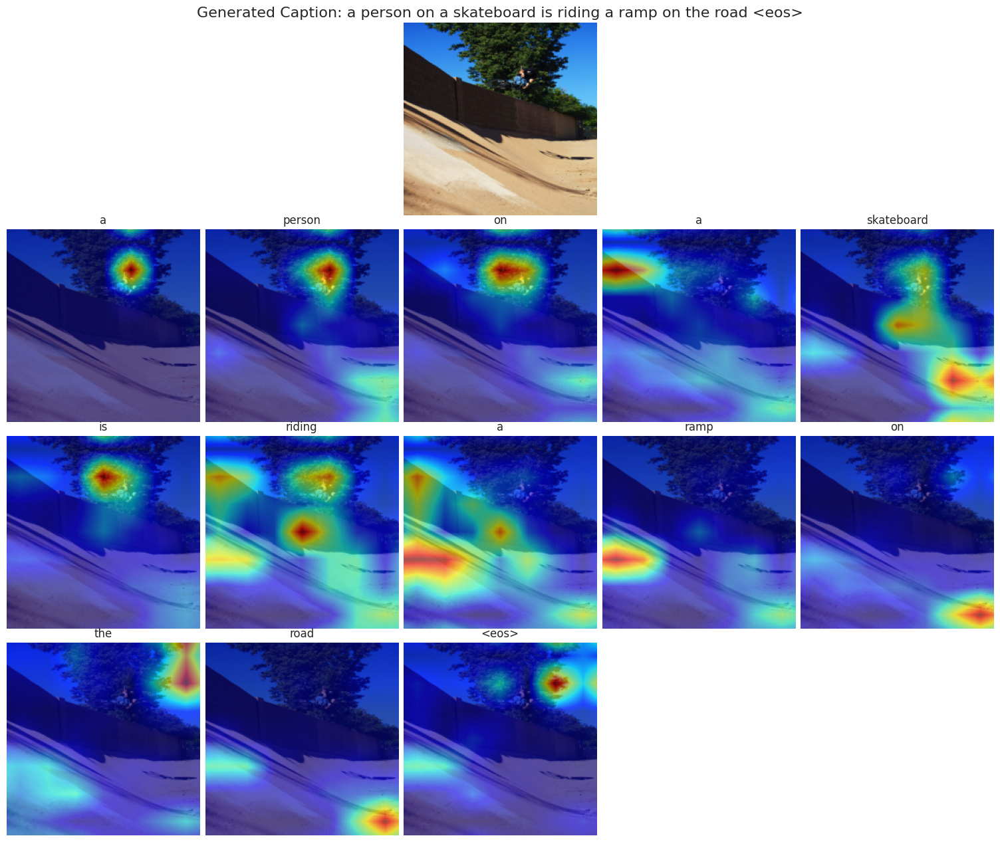


--- Generating Example with Attention Visualization ---
index = 4658
feature = 5000
dataset = 5000


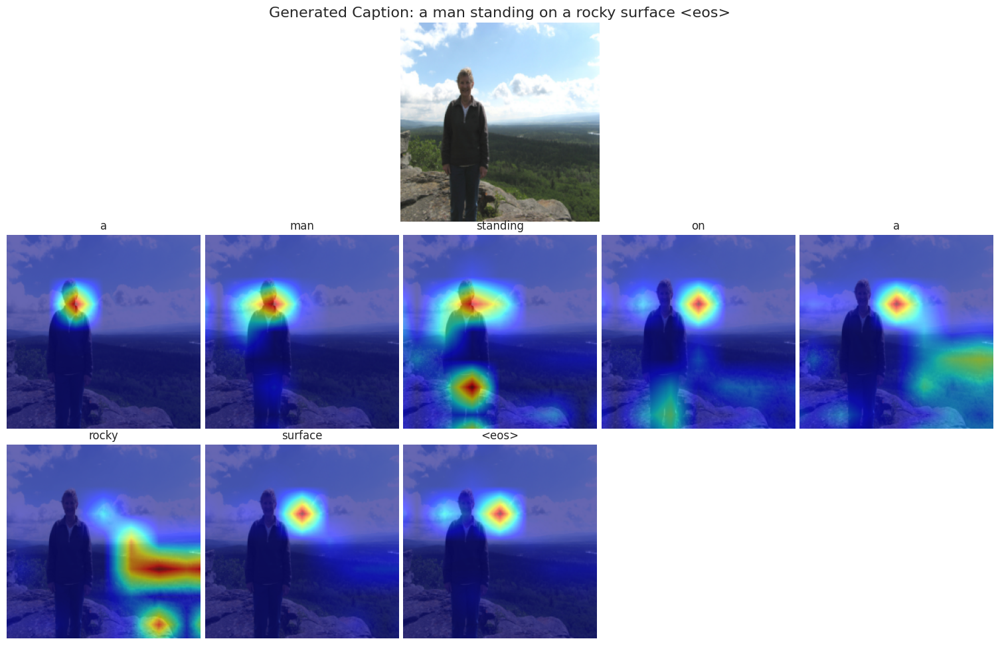

In [26]:
# --- Plot Loss Curves ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses_att, label='Training Loss (Attention)')
plt.plot(val_losses_att, label='Validation Loss (Attention)')
plt.title('Attention Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# --- Show 5 Final Examples ---
print("\n--- Final Results on Test Set (with Attention Heatmaps) ---")
# (You might need to recreate the test_loader with the collate_fn)
generate_and_visualize_attention(model=model_fast, feature_dataset=val_loader_precomp.dataset, image_dataset=val_dataset, vocab=vocab, device=device)


## Analysis of Image Captioning Heatmap (Last Image)

The image shows an example of **attention visualization** from an image captioning model.  
The generated caption is: **"a man standing on a rocky surface <eos>"**.  
Below the image, heatmaps illustrate which regions of the input image the model attended to while predicting each word in the caption.

---

### Observations

1. **Word "a" (first occurrence):**
   - The model's attention is concentrated around the man’s head.
   - Suggests that the model begins by focusing on the central subject before specifying identity.

2. **Word "man":**
   - Strong attention around the head and upper torso.
   - Indicates the model associates facial/head regions with identifying a "man."

3. **Word "standing":**
   - Attention spans the entire body from head to feet.
   - The model correctly learns that "standing" requires understanding posture.

4. **Word "on":**
   - Attention shifts slightly lower, near the torso.
   - Suggests the model is transitioning toward describing spatial relation ("on").

5. **Word "a" (second occurrence):**
   - Distributed attention: upper body and part of the ground.
   - Prepares to introduce the object (surface).

6. **Word "rocky":**
   - Strong attention on the rocks near the man’s feet and ground.
   - Accurately highlights the rocky surface.

7. **Word "surface":**
   - Attention slightly returns toward the man and nearby ground.
   - Confirms grounding of the word "surface."

8. **Word "<eos>" (end of sentence):**
   - Focus returns to the man’s head.
   - Suggests closure of caption generation.

---

### Key Insights

- The heatmaps align well with human intuition:  
  - **Subject identification** ("man") → focuses on head/torso.  
  - **Action/state** ("standing") → full body posture.  
  - **Scene context** ("rocky surface") → ground/rocks near the feet.  

- The model demonstrates **semantic grounding**, attending to relevant visual features for each predicted token.  
- Some redundancy is observed (e.g., focus on the man even when describing "surface"), which might be due to the model's strong bias toward the central figure.

---

### Conclusion

This visualization confirms that the captioning model effectively learns to align **linguistic tokens with visual regions**, showcasing interpretable attention behavior. While not perfect, the attention maps suggest a strong link between generated words and image regions, validating the plausibility of the generated caption.


In [22]:
model_loaded = DecoderOnly_AttentionModel(embed_size, hidden_size, vocab_size).to(device)

checkpoint = torch.load("attention_checkpoint.pth.tar", map_location="cuda")
model_loaded.load_state_dict(checkpoint["state_dict"])
model_loaded.eval()


DecoderOnly_AttentionModel(
  (decoder): DecoderRNN_Attention(
    (embedding): Embedding(2957, 256)
    (attention): Attention(
      (encoder_att): Linear(in_features=1280, out_features=512, bias=True)
      (decoder_att): Linear(in_features=512, out_features=512, bias=True)
      (full_att): Linear(in_features=512, out_features=1, bias=True)
      (relu): ReLU()
      (softmax): Softmax(dim=1)
    )
    (lstm_cell): LSTMCell(1536, 512)
    (init_h): Linear(in_features=1280, out_features=512, bias=True)
    (init_c): Linear(in_features=1280, out_features=512, bias=True)
    (fcn): Linear(in_features=512, out_features=2957, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
  )
)

20
a man in a red uniform and white shirt is on a football <eos>

--- Example Prediction (Pre-computed) ---


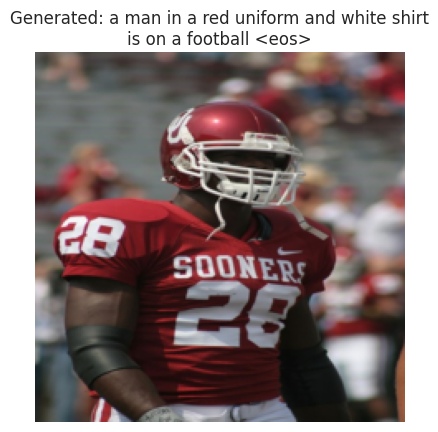

45
a group of men playing basketball <eos>

--- Example Prediction (Pre-computed) ---


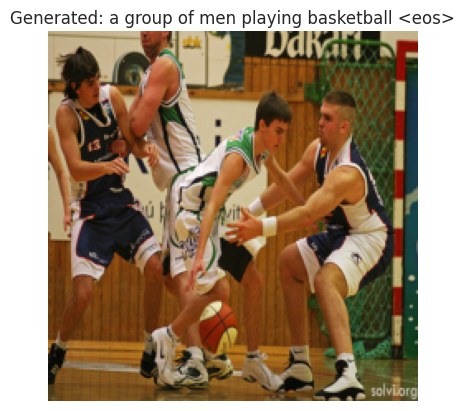

70
a man in a hat sits on a rock wall and is looking into the water <eos>

--- Example Prediction (Pre-computed) ---


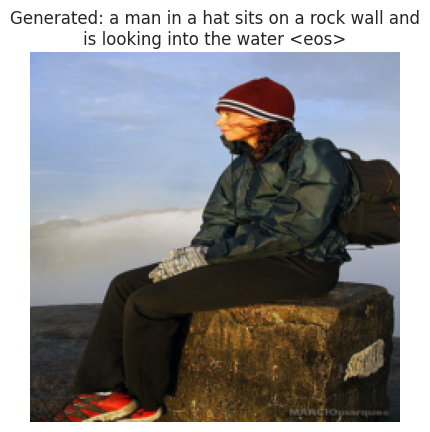

80
a black dog is chasing a blue and brown dog on a blue toy <eos>

--- Example Prediction (Pre-computed) ---


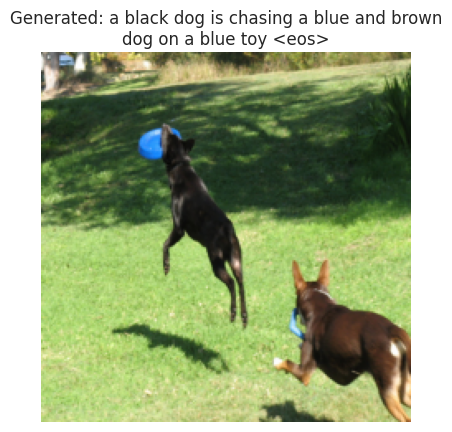

115
a skateboarder in a red shirt and a blue shirt is performing tricks on the street <eos>

--- Example Prediction (Pre-computed) ---


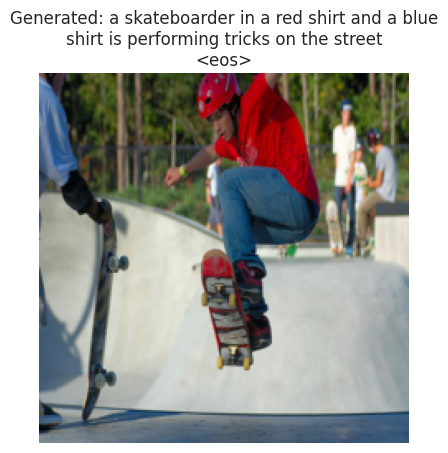

220
a man stands near a mountain <eos>

--- Example Prediction (Pre-computed) ---


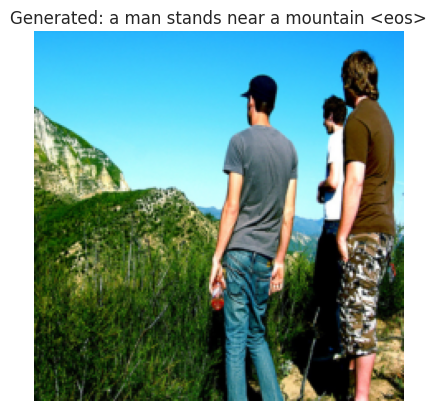

In [37]:
ids = [20, 45, 70 , 80 , 115,220]
results = {}
for i in ids:
    print(i)
    g = show_example_prediction_by_id(model=model_loaded, feature_dataset=test_loader_precomp.dataset, image_dataset=test_dataset,vocab = vocab, device=device , idx=i)
    results[i] = g

In [38]:
results

{20: 'a man in a red uniform and white shirt is on a football <eos>',
 45: 'a group of men playing basketball <eos>',
 70: 'a man in a hat sits on a rock wall and is looking into the water <eos>',
 80: 'a black dog is chasing a blue and brown dog on a blue toy <eos>',
 115: 'a skateboarder in a red shirt and a blue shirt is performing tricks on the street <eos>',
 220: 'a man stands near a mountain <eos>'}

In [39]:
import json
with open ("attention_results.json" , "w") as f:
    json.dump(results , f)

## Qualitative Comparison and Error Analysis

At the end of the last model, in evaluation parts all comparisions are done